# Детекция и сегментация планктонных организмов на микроскопических изображениях

Лабораторная работа: предобученные детекторы (YOLOv8n - одноэтапный, Faster R-CNN - двухэтапный), аугментации, сегментация по рамкам (GrabCut и SAM 2) на **неразмеченных** микроскопических снимках.

Ноутбук работает в Google Colab (T4 GPU) и вне его (тогда пути берутся от текущей папки; для SAM 2 нужен GPU). Изображения скачиваются из публичной папки Google Drive (`gdown`), все результаты (CSV/JSON, рамки, маски, визуализации) сохраняются в `results/`.

> ⚠️ Модели обучены на COCO - класса «планктон» там нет. Предсказания - лишь гипотезы. mAP/Precision/Recall без эталона не считаются; confidence - не вероятность «это организм». Любые ложные срабатывания/пропуски ниже - оценка только по визуальному осмотру и эвристике.

**Структура:**                  \
0 - окружение и настройки       \
1 - данные и аугментации        \
2 - детекция (4 эксперимента)   \
3 - сегментация                 \
4 - сравнительные таблицы, анализ ошибок, выводы \
5 - проверка и экспорт.

## 0. Окружение и настройки

In [1]:
# Версии ultralytics/gdown зафиксированы (с ними ноутбук был запущен); torch/torchvision - из Colab.
%pip install -q "ultralytics==8.4.216" "gdown==5.2.2" scipy sam2

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import sys, time, platform, random, warnings, json, zlib, subprocess
import importlib.metadata as importlib_metadata
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown
import torch

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


# ======================= НАСТРОЙКИ =======================
SEED = 42
#                         |                                             |< 45 символов
PUBLIC_DRIVE_FOLDER_URL = 'https://drive.google.com/drive/folders/<ID>'
USE_DRIVE_FOR_DATA   = True     # Colab: хранить данные/результаты на Google Drive
DRIVE_PROJECT_SUBDIR = 'Colab Notebooks/Детекция и сегментация/HW3'
FORCE_REDOWNLOAD     = False
MAX_IMAGES           = None     # None = все изображения

# --- детекция (одинаково для обеих моделей) ---
DET_CONF        = 0.15   # основной порог confidence
DET_CONF_STORE  = 0.05   # сохраняем всё от этого порога (для анализа чувствительности к порогу)
DET_NMS_IOU     = 0.5    # IoU для NMS (класс-независимый у обеих моделей)
DET_MAX         = 100
YOLO_WEIGHTS    = 'yolov8n.pt'
YOLO_IMGSZ      = 1024   # Faster R-CNN внутри масштабирует кадр до ~800-1333 px; 640 у YOLO терял бы мелкие объекты
DET_AUG_NAMES   = ['bc_medium', 'noise_medium', 'noise_strong', 'blur_medium', 'blur_strong',
                   'gamma_medium', 'rot90', 'flip_h']   # аугментации для экспериментов 2 и 4
PRIMARY_AUG     = 'bc_medium'   # вариант, для которого сохраняются панели 2x2 по всем изображениям
STABILITY_IOU   = 0.5

# --- сегментация ---
SEGMENTATION_DETECTOR = 'auto'  # 'auto' | 'YOLOv8n' | 'FasterRCNN' (auto: больше изображений с пригодными рамками)
SEG_MAX_BOX_AREA_FRAC = 0.6     # рамки больше 60% кадра# --- детекция (одинаково для обеих моделей) ---
# основной порог confidence
DET_CONF = 0.15
# сохраняем всё от этого порога (для анализа чувствительности к порогу)
DET_CONF_STORE = 0.05
# IoU для NMS (класс-независимый у обеих моделей)
DET_NMS_IOU = 0.5
DET_MAX = 100
YOLO_WEIGHTS = 'yolov8n.pt'
# Faster R-CNN внутри масштабирует кадр до ~800-1333 px; 640 у YOLO терял бы мелкие объекты
YOLO_IMGSZ = 1024
# аугментации для экспериментов 2 и 4
DET_AUG_NAMES = [
    'bc_medium', 'noise_medium', 'noise_strong', 'blur_medium',
    'blur_strong', 'gamma_medium', 'rot90', 'flip_h',
]
# вариант, для которого сохраняются панели 2x2 по всем изображениям
PRIMARY_AUG = 'bc_medium'
STABILITY_IOU = 0.5

# --- сегментация ---
# 'auto' | 'YOLOv8n' | 'FasterRCNN' (auto: больше изображений с пригодными рамками)
SEGMENTATION_DETECTOR = 'auto'
# рамки больше 60% кадра в сегментацию не идут
SEG_MAX_BOX_AREA_FRAC = 0.6
SEG_MIN_BOX_SIDE = 100
GRABCUT_ITERS = 5
# запас вокруг рамки при вырезании кроп-окна (ускоряет GrabCut, даёт фон для GMM)
GRABCUT_MARGIN = 0.15
SAM2_CONFIG = 'configs/sam2.1/sam2.1_hiera_l.yaml'
SAM2_URL = (
    'https://dl.fbaipublicfiles.com/segment_anything_2/092824/'
    'sam2.1_hiera_large.pt'
)
# для box-подсказки рекомендуется одна маска
SAM2_MULTIMASK = False
# {'file.jpg': [{'x1':..,'y1':..,'x2':..,'y2':..,'label':'manual','score':1.0}]} - только для кадров без рамок детектора
MANUAL_BOXES = {}
# число рамок в тесте устойчивости сегментации (шум / неточные рамки)
ROBUST_N_BOXES = 40


# ======================= ПУТИ =======================
if IN_COLAB and USE_DRIVE_FOR_DATA:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive') / DRIVE_PROJECT_SUBDIR
elif IN_COLAB:
    PROJECT_ROOT = Path('/content/plankton_lab')
else:
    PROJECT_ROOT = Path.cwd()

IMAGE_DIR = PROJECT_ROOT / 'data' / 'images'
RESULTS_DIR = PROJECT_ROOT / 'results'
AUG_DIR = RESULTS_DIR / 'augmentations'
DET_DIR = RESULTS_DIR / 'detections'
TABLE_DIR = RESULTS_DIR / 'tables'
SEG_DIR = RESULTS_DIR / 'segmentation'
MASK_DIR = SEG_DIR / 'masks'
PANEL_DIR = SEG_DIR / 'panels'
OVERLAY_DIR = SEG_DIR / 'overlays'
ANALYSIS_DIR = RESULTS_DIR / 'analysis'
CKPT_DIR = PROJECT_ROOT / 'checkpoints'

all_dirs = [
    IMAGE_DIR, AUG_DIR, DET_DIR, TABLE_DIR, MASK_DIR,
    PANEL_DIR, OVERLAY_DIR, ANALYSIS_DIR, CKPT_DIR,
]
for directory in all_dirs:
    directory.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


def pkg_version(name):
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return 'not installed'


package_names = [
    'torch', 'torchvision', 'ultralytics', 'opencv-python', 'numpy',
    'pandas', 'matplotlib', 'scipy', 'Pillow', 'gdown', 'sam2',
]
gpu_name = torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None

ENV = {
    'python': platform.python_version(),
    'platform': platform.platform(),
    'device': DEVICE,
    'gpu': gpu_name,
    'packages': {name: pkg_version(name) for name in package_names},
}

config_types = (int, float, str, bool, list, dict, type(None))
RUN_CONFIG = {}
for key, value in list(globals().items()):
    if key.isupper() and key != 'ENV' and isinstance(value, config_types):
        RUN_CONFIG[key] = value

env_json = json.dumps(ENV, ensure_ascii=False, indent=2)
config_json = json.dumps(RUN_CONFIG, ensure_ascii=False, indent=2, default=str)
(RESULTS_DIR / 'environment.json').write_text(env_json)
(RESULTS_DIR / 'run_config.json').write_text(config_json)

print(json.dumps(ENV, ensure_ascii=False, indent=2))
print('PROJECT_ROOT:', PROJECT_ROOT)

Mounted at /content/drive
{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "device": "cuda",
  "gpu": "Tesla T4",
  "packages": {
    "torch": "2.14.1+cu130",
    "torchvision": "0.29.1+cu130",
    "ultralytics": "8.4.216",
    "opencv-python": "5.0.0.93",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0",
    "scipy": "1.16.3",
    "Pillow": "11.3.0",
    "gdown": "5.2.2",
    "sam2": "1.1.0"
  }
}
PROJECT_ROOT: /content/drive/MyDrive/Colab Notebooks/Детекция и сегментация/HW3


### Данные
Папка Drive должна быть доступна «всем, у кого есть ссылка». **Исходные изображения в репозиторий не добавляются без разрешения** - вместо этого они подключаются по ссылке выше (`gdown`) и кладутся в `data/images/`.

In [3]:
import gdown


IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp', '.gif', '.webp'}


def list_images(root):
    found = []
    for path in Path(root).rglob('*'):
        if not path.is_file():
            continue
        if path.name.startswith(('.', '._')):
            continue
        if path.suffix.lower() in IMAGE_EXTS:
            found.append(path)
    return sorted(found)


before = list_images(IMAGE_DIR)

if FORCE_REDOWNLOAD or (len(before) == 0):
    if len(PUBLIC_DRIVE_FOLDER_URL) < 45:
        print('⚠️ Задайте PUBLIC_DRIVE_FOLDER_URL или положите изображения в', IMAGE_DIR)
    else:
        for attempt in range(1, 4):
            try:
                gdown.download_folder(
                    url=PUBLIC_DRIVE_FOLDER_URL,
                    output=str(IMAGE_DIR),
                    quiet=True,
                    use_cookies=False,
                    remaining_ok=True,
                )
                break
            except Exception as e:
                print(f'попытка {attempt}: {e}')
                time.sleep(5)
else:
    print('Изображения уже есть, скачивание пропущено.')


def load_rgb(path):
    """HxWx3 uint8 (записываемый массив), учитывает EXIF-ориентацию; None при ошибке."""
    try:
        img = Image.open(path)
        if getattr(img, 'n_frames', 1) > 1:
            img.seek(0)
        img = ImageOps.exif_transpose(img).convert('RGB')
        return np.array(img)
    except Exception as e:
        print(f'  [skip] {path}: {e}')
        return None


all_images = list_images(IMAGE_DIR)

image_paths = []
for path in all_images:
    if load_rgb(path) is not None:
        image_paths.append(path)

if MAX_IMAGES:
    image_paths = image_paths[:MAX_IMAGES]


PATH_BY_NAME = {path.name: path for path in image_paths}
paths_for_exp = image_paths
print(f'Файлов: {len(all_images)}, читаемых и взятых в работу: {len(image_paths)}')

Изображения уже есть, скачивание пропущено.
Файлов: 50, читаемых и взятых в работу: 50


## 1. Анализ и аугментация изображений
### 1.1 Анализ исходных данных
Для каждого снимка считаются: разрешение, яркость, контраст (σ серого), неоднородность фона и - **приближённо, классическим методом без разметки** - число тёмных объектов, их размеры, контраст объект/фон и «возможные перекрытия». Метод: сглаживание -> оценка фона медианным фильтром большого окна -> порог Оцу по разности «фон - пиксель» -> морфология -> компоненты связности. Это ориентир для анализа и для эвристической проверки детекторов, а не разметка: нити, пыль и слипшиеся организмы он может считать объектами/одним объектом (поэтому результат проверяется визуально на примерах ниже).

In [4]:
ANALYSIS_WIDTH, MIN_BLOB_AREA, MERGE_AREA_RATIO, MERGE_SOLIDITY = 1024, 400, 2.2, 0.85
FG_CACHE = {}   # имя файла -> (маска «объектов» в масштабе анализа, масштаб)

def analyze_image(path):
    rgb = load_rgb(path)
    gray_full = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    H, W = gray_full.shape
    s = ANALYSIS_WIDTH / W

    new_size = (ANALYSIS_WIDTH, int(round(H * s)))
    gray = cv2.resize(gray_full, new_size, interpolation=cv2.INTER_AREA)
    sm = cv2.GaussianBlur(gray, (0, 0), 1.5)
    bg = cv2.medianBlur(sm, (ANALYSIS_WIDTH // 6) | 1)
    diff = cv2.subtract(bg, sm)

    otsu_flags = cv2.THRESH_BINARY + cv2.THRESH_OTSU
    otsu_thr = cv2.threshold(diff, 0, 255, otsu_flags)[0]
    thr = max(10.0, float(otsu_thr))
    fg = (diff > thr).astype(np.uint8)

    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    fg = cv2.morphologyEx(fg, cv2.MORPH_OPEN, kernel_open)
    fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, kernel_close)

    n, lab, st, _ = cv2.connectedComponentsWithStats(fg, connectivity=8)
    keep = np.zeros_like(fg)
    comps = []
    small = 0
    hs, ws = fg.shape

    for i in range(1, n):
        area = int(st[i, cv2.CC_STAT_AREA])

        if area < MIN_BLOB_AREA:
            small += int(area >= 30)
            continue

        comp = lab == i
        keep[comp] = 1

        contours, _ = cv2.findContours(
            comp.astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE,
        )
        contour = max(contours, key=cv2.contourArea)
        hull_area = cv2.contourArea(cv2.convexHull(contour))

        solidity = 1.0
        if hull_area > 0:
            solidity = float(cv2.contourArea(contour) / hull_area)

        x, y, w, h = [int(v) for v in st[i, :4]]
        bg_median = float(np.median(bg[comp]))
        obj_median = float(np.median(sm[comp]))
        contrast = (bg_median - obj_median) / max(bg_median + obj_median, 1.0)
        touches_border = x <= 1 or y <= 1 or x + w >= ws - 1 or y + h >= hs - 1

        comps.append({
            'file': path.name,
            'x1': x / s,
            'y1': y / s,
            'x2': (x + w) / s,
            'y2': (y + h) / s,
            'area_px': area / s ** 2,
            'eq_diam_px': 2 * np.sqrt(area / np.pi) / s,
            'solidity': solidity,
            'contrast': contrast,
            'touches_border': bool(touches_border),
        })

    FG_CACHE[path.name] = (keep, s)

    areas = [c['area_px'] for c in comps]
    med = float(np.median(areas)) if comps else np.nan

    for c in comps:
        is_large = len(comps) >= 3 and c['area_px'] > MERGE_AREA_RATIO * med
        c['merged_candidate'] = bool(is_large or c['solidity'] < MERGE_SOLIDITY)

    diameters = [c['eq_diam_px'] for c in comps]
    contrasts = [c['contrast'] for c in comps]
    median_diam = float(np.median(diameters)) if comps else np.nan
    mean_contrast = float(np.mean(contrasts)) if comps else np.nan
    bg_nonuniformity = np.percentile(bg, 95) - np.percentile(bg, 5)

    row = {
        'file': path.name,
        'width': W,
        'height': H,
        'megapixels': W * H / 1e6,
        'mean_gray': float(gray_full.mean()),
        'std_gray': float(gray_full.std()),
        'p05_gray': float(np.percentile(gray_full, 5)),
        'p95_gray': float(np.percentile(gray_full, 95)),
        'dark_fraction_lt20': float((gray_full < 20).mean()),
        'bright_fraction_gt235': float((gray_full > 235).mean()),
        'bg_nonuniformity': float(bg_nonuniformity),
        'n_blobs': len(comps),
        'n_small_debris': small,
        'fg_fraction': float(keep.mean()),
        'median_eq_diam_px': median_diam,
        'max_area_frac': max(areas, default=0) / (W * H),
        'mean_obj_contrast': mean_contrast,
        'n_merged_candidates': sum(c['merged_candidate'] for c in comps),
        'n_touch_border': sum(c['touches_border'] for c in comps),
    }

    return row, comps


analysis_results = [analyze_image(p) for p in image_paths]

stats_df = pd.DataFrame([row for row, _ in analysis_results])
blobs_df = pd.DataFrame([c for _, comps in analysis_results for c in comps])

BLOBS_BY_FILE = {}
if len(blobs_df):
    for file_name, group in blobs_df.groupby('file'):
        BLOBS_BY_FILE[file_name] = group.to_dict('records')

stats_df.to_csv(TABLE_DIR / 'image_statistics.csv', index=False)
blobs_df.to_csv(TABLE_DIR / 'blob_estimates.csv', index=False)

with pd.option_context('display.max_rows', None, 'display.width', 250, 'display.max_columns', None):
    display(stats_df.round(3))

display(stats_df.drop(columns='file').describe().T.round(3))

res_counts = stats_df.groupby(['width', 'height']).size()
res_counts = res_counts.rename('n_images').reset_index()
display(res_counts)
print()

diam = blobs_df.eq_diam_px
summary_text = (
    f"**Итого:** {len(stats_df)} изображений, {len(res_counts)} разреш. вариант(а); "
    f"яркость {stats_df.mean_gray.min():.0f}-{stats_df.mean_gray.max():.0f}; "
    f"σ серого {stats_df.std_gray.min():.1f}-{stats_df.std_gray.max():.1f}; "
    f"объектов на кадр (оценка) {stats_df.n_blobs.min()}-{stats_df.n_blobs.max()} "
    f"(медиана {stats_df.n_blobs.median():.0f}); "
    f"медианный эквив. диаметр {diam.median():.0f} px "
    f"(5-95 перц.: {diam.quantile(.05):.0f}-{diam.quantile(.95):.0f}); "
    f"кадров с «возможными перекрытиями»: {(stats_df.n_merged_candidates > 0).sum()}."
)
display(Markdown(summary_text))

,file,width,height,megapixels,mean_gray,std_gray,p05_gray,p95_gray,dark_fraction_lt20,bright_fraction_gt235,bg_nonuniformity,n_blobs,n_small_debris,fg_fraction,median_eq_diam_px,max_area_frac,mean_obj_contrast,n_merged_candidates,n_touch_border
0,0005.jpg,2592,1944,5.039,108.742,43.694,29.0,153.0,0.002,0.0,118.0,14,24,0.068,139.213,0.019,0.114,12,3
1,20250213131616824.jpg,2048,1536,3.146,182.846,30.957,95.0,204.0,0.000,0.0,38.0,6,8,0.124,293.245,0.025,0.262,4,1
2,20250213131626559.jpg,2048,1536,3.146,176.463,29.414,93.0,196.0,0.000,0.0,49.0,7,12,0.110,255.742,0.025,0.263,5,1
3,20250213131634306.jpg,2048,1536,3.146,183.500,20.025,152.0,196.0,0.000,0.0,15.0,4,9,0.043,191.279,0.022,0.270,1,1
4,20250213131652198.jpg,2048,1536,3.146,173.031,27.303,91.0,189.0,0.000,0.0,89.0,2,13,0.047,257.245,0.045,0.109,2,0
5,20250213131707578.jpg,2048,1536,3.146,183.413,15.004,166.0,190.0,0.000,0.0,2.0,15,9,0.034,95.453,0.006,0.255,4,1
6,20250213131717749.jpg,2048,1536,3.146,186.132,13.618,177.0,194.0,0.000,0.0,7.0,11,6,0.025,98.137,0.003,0.266,1,2
7,20250213131733581.jpg,2048,1536,3.146,186.340,18.089,161.0,197.0,0.000,0.0,13.0,6,5,0.040,182.523,0.013,0.271,3,0
8,20250213131756895.jpg,2048,1536,3.146,180.592,16.251,158.0,188.0,0.000,0.0,5.0,12,6,0.042,123.370,0.005,0.257,2,0
9,20250213131804115.jpg,2048,1536,3.146,178.210,18.404,137.0,187.0,0.000,0.0,5.0,14,4,0.053,121.337,0.007,0.270,5,1


,count,mean,std,min,25%,50%,75%,max
width,50.0,2058.880,76.933,2048.000,2048.000,2048.000,2048.000,2592.000
height,50.0,1544.160,57.700,1536.000,1536.000,1536.000,1536.000,1944.000
megapixels,50.0,3.184,0.268,3.146,3.146,3.146,3.146,5.039
mean_gray,50.0,180.755,11.589,108.742,178.500,180.953,186.288,194.907
std_gray,50.0,23.708,7.688,12.106,18.175,21.886,29.043,43.694
p05_gray,50.0,125.540,34.357,29.000,95.500,123.500,153.000,181.000
p95_gray,50.0,195.520,8.728,153.000,193.250,196.000,199.000,218.000
dark_fraction_lt20,50.0,0.000,0.000,0.000,0.000,0.000,0.000,0.002
bright_fraction_gt235,50.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
bg_nonuniformity,50.0,38.840,37.584,2.000,13.000,18.500,69.000,118.000


,width,height,n_images
0,2048,1536,49
1,2592,1944,1


**Итого:** 50 изображений, 2 разреш. вариант(а); яркость 109–195; σ серого 12.1–43.7; объектов на кадр (оценка) 2–23 (медиана 8); медианный эквив. диаметр 108 px (5–95 перц.: 49–296); кадров с «возможными перекрытиями»: 49.

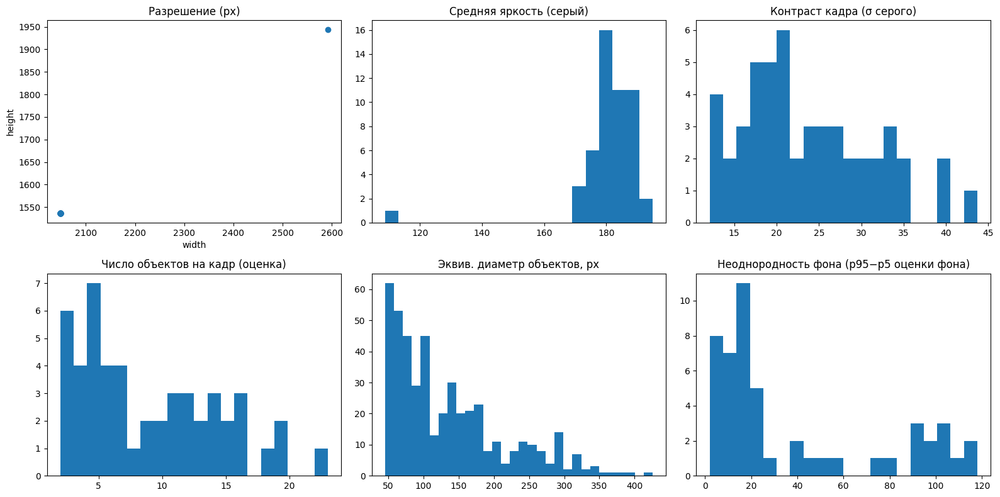

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax = ax.ravel()

ax[0].scatter(stats_df.width, stats_df.height)
ax[0].set_title('Разрешение (px)')
ax[0].set_xlabel('width')
ax[0].set_ylabel('height')

ax[1].hist(stats_df.mean_gray, 20)
ax[1].set_title('Средняя яркость (серый)')

ax[2].hist(stats_df.std_gray, 20)
ax[2].set_title('Контраст кадра (σ серого)')

ax[3].hist(stats_df.n_blobs, 20)
ax[3].set_title('Число объектов на кадр (оценка)')

ax[4].hist(blobs_df.eq_diam_px, 30)
ax[4].set_title('Эквив. диаметр объектов, px')

ax[5].hist(stats_df.bg_nonuniformity, 20)
ax[5].set_title('Неоднородность фона (p95−p5 оценки фона)')

plt.tight_layout()
fig.savefig(ANALYSIS_DIR / 'data_histograms.png', dpi=110)
plt.show()

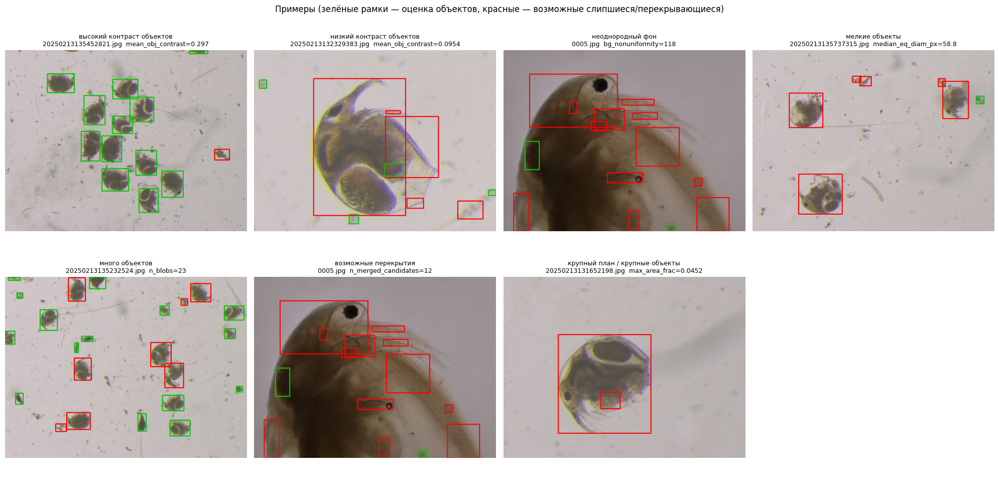

In [6]:
def pick(df, col, mode, cond=None):
    d = df if cond is None else df[cond(df)]
    d = d.dropna(subset=[col])

    if not len(d):
        return None

    if mode == 'max':
        return d.loc[d[col].idxmax()]
    return d.loc[d[col].idxmin()]


EX = {
    'высокий контраст объектов': (
        pick(stats_df, 'mean_obj_contrast', 'max'), 'mean_obj_contrast'),
    'низкий контраст объектов': (
        pick(stats_df, 'mean_obj_contrast', 'min'), 'mean_obj_contrast'),
    'неоднородный фон': (
        pick(stats_df, 'bg_nonuniformity', 'max'), 'bg_nonuniformity'),
    'мелкие объекты': (
        pick(stats_df, 'median_eq_diam_px', 'min', lambda d: d.n_blobs >= 3),
        'median_eq_diam_px'),
    'много объектов': (
        pick(stats_df, 'n_blobs', 'max'), 'n_blobs'),
    'возможные перекрытия': (
        pick(stats_df, 'n_merged_candidates', 'max'), 'n_merged_candidates'),
    'крупный план / крупные объекты': (
        pick(stats_df, 'max_area_frac', 'max'), 'max_area_frac'),
}

EX = {k: v for k, v in EX.items() if v[0] is not None}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for ax, (title, (row, col)) in zip(axes, EX.items()):
    rgb = load_rgb(PATH_BY_NAME[row.file])
    sc = 700 / rgb.shape[1]
    img = cv2.resize(rgb, None, fx=sc, fy=sc, interpolation=cv2.INTER_AREA)

    for c in BLOBS_BY_FILE.get(row.file, []):
        top_left = (int(c['x1'] * sc), int(c['y1'] * sc))
        bottom_right = (int(c['x2'] * sc), int(c['y2'] * sc))
        color = (255, 0, 0) if c['merged_candidate'] else (0, 200, 0)
        cv2.rectangle(img, top_left, bottom_right, color, 2)

    ax.imshow(img)
    ax.set_title(f'{title}\n{row.file}  {col}={row[col]:.3g}', fontsize=9)
    ax.axis('off')

for ax in axes[len(EX):]:
    ax.axis('off')

plt.suptitle('Примеры (зелёные рамки - оценка объектов, красные - возможные слипшиеся/перекрывающиеся)')
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / 'data_examples.png', dpi=100)
plt.show()

**Наблюдения по данным** (по галерее и таблицам выше; точные числа - в `image_statistics.csv`):
- **Разрешение:** почти все кадры 2048×1536, одиночный кадр `0005.jpg` - 2592×1944 и иного типа (макро-снимок одного крупного организма на тёмно-сером фоне, соответственно, самая низкая средняя яркость в наборе). Это выброс, на нём все методы ведут себя иначе.
- **Фон:** светлый, серый, с виньетированием/градиентом, пылью, волокнами и нитями, пятнами вне фокуса, пузырьками. Это источники ложных срабатываний.
- **Контраст:** объекты тёмно-коричневые на светлом фоне, но с полупрозрачными панцирями и слабоконтрастными щетинками/антеннами: границы тела чёткие, а тонкие придатки - не всегда. Общий σ серого невысокий (десятки уровней), на части кадров он очень мал.
- **Размеры и число:** от одиночных крупных организмов (сотни px) до 10-20 мелких на кадр (по ~100 пикселей); много организмов частично обрезаны краем кадра.
- **Перекрытия:** встречаются касающиеся/слипшиеся пары и скопления, но их в датасете немного.

### 1.2 Аугментации
Реализованы: яркость/контраст, гауссов шум, гауссово размытие, гамма-коррекция, поворот (на 90° без потерь и на 15° с однотонной заливкой), отражения, масштабирование. Для яркости/контраста, шума, размытия и гаммы - **три уровня интенсивности**. Шум детерминирован (seed от имени файла и аугментации). Для скейла/поворота на угол заливка - медианный цвет фона (отражение создало бы «фантомные» организмы).

Аугментированные кадры для детекции генерируются, не сохраняются: 50×18 PNG по 3 Мп весят многовато. Сохраняются параметры (`augmentation_manifest.csv`), панели и кропы.

Демо-изображение: 20250213132044082.jpg


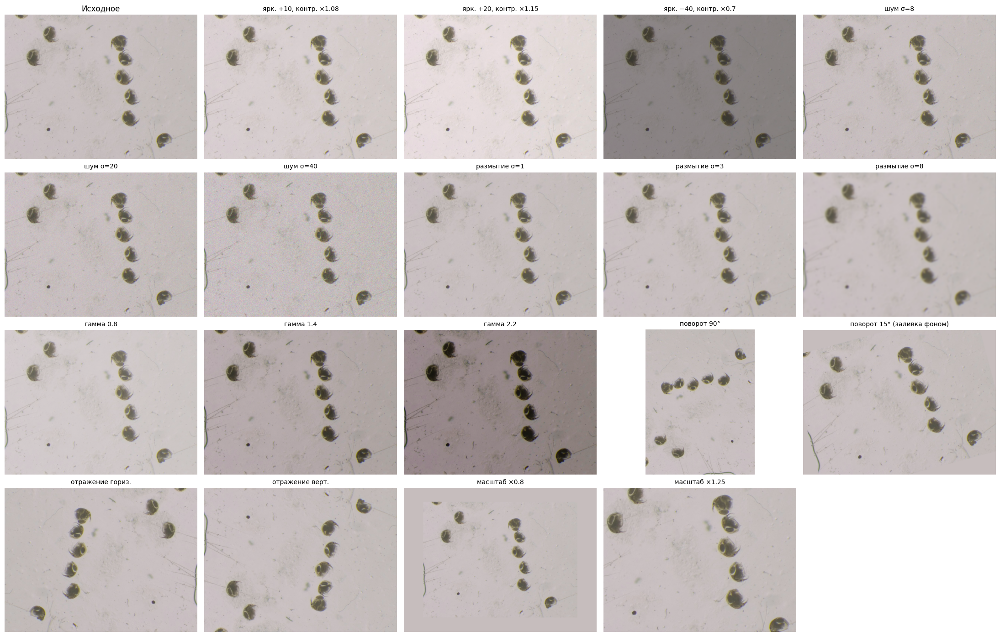

In [7]:
def _bg_color(rgb):
    pixels = rgb[::8, ::8].reshape(-1, 3)
    return tuple(float(v) for v in np.median(pixels, axis=0))


def augment_image(rgb, kind, level, rng=None):
    rng = rng if rng is not None else np.random.default_rng(SEED)

    if kind == 'rotate90':
        return np.ascontiguousarray(np.rot90(rgb, k=int(level)))

    if kind == 'flip':
        flipped = rgb[:, ::-1] if level == 'h' else rgb[::-1]
        return np.ascontiguousarray(flipped)

    if kind in ('rotate', 'scale'):
        h, w = rgb.shape[:2]
        if kind == 'rotate':
            angle, scale = float(level), 1.0
        else:
            angle, scale = 0.0, float(level)
        M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
        return cv2.warpAffine(
            rgb, M, (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=_bg_color(rgb),
        )

    x = rgb.astype(np.float32)

    if kind == 'brightness_contrast':
        brightness, contrast = level
        y = (x - 127.5) * contrast + 127.5 + brightness
    elif kind == 'gaussian_noise':
        noise = rng.normal(0, float(level), x.shape).astype(np.float32)
        y = x + noise
    elif kind == 'gaussian_blur':
        blurred = cv2.GaussianBlur(rgb, (0, 0), sigmaX=float(level))
        y = blurred.astype(np.float32)
    elif kind == 'gamma':
        y = 255.0 * np.power(np.clip(x / 255.0, 0, 1), float(level))
    else:
        raise ValueError(kind)

    return np.clip(y, 0, 255).astype(np.uint8)


AUGMENTATIONS = [
    dict(name='bc_weak', kind='brightness_contrast', level=(10, 1.08),
         group='яркость/контраст', label='ярк. +10, контр. ×1.08'),
    dict(name='bc_medium', kind='brightness_contrast', level=(20, 1.15),
         group='яркость/контраст', label='ярк. +20, контр. ×1.15'),
    dict(name='bc_strong', kind='brightness_contrast', level=(-40, 0.7),
         group='яркость/контраст', label='ярк. −40, контр. ×0.7'),
    dict(name='noise_weak', kind='gaussian_noise', level=8,
         group='шум', label='шум σ=8'),
    dict(name='noise_medium', kind='gaussian_noise', level=20,
         group='шум', label='шум σ=20'),
    dict(name='noise_strong', kind='gaussian_noise', level=40,
         group='шум', label='шум σ=40'),
    dict(name='blur_weak', kind='gaussian_blur', level=1,
         group='размытие', label='размытие σ=1'),
    dict(name='blur_medium', kind='gaussian_blur', level=3,
         group='размытие', label='размытие σ=3'),
    dict(name='blur_strong', kind='gaussian_blur', level=8,
         group='размытие', label='размытие σ=8'),
    dict(name='gamma_weak', kind='gamma', level=0.8,
         group='гамма', label='гамма 0.8'),
    dict(name='gamma_medium', kind='gamma', level=1.4,
         group='гамма', label='гамма 1.4'),
    dict(name='gamma_strong', kind='gamma', level=2.2,
         group='гамма', label='гамма 2.2'),
    dict(name='rot90', kind='rotate90', level=1,
         group='геометрия', label='поворот 90°'),
    dict(name='rot15', kind='rotate', level=15,
         group='геометрия', label='поворот 15° (заливка фоном)'),
    dict(name='flip_h', kind='flip', level='h',
         group='геометрия', label='отражение гориз.'),
    dict(name='flip_v', kind='flip', level='v',
         group='геометрия', label='отражение верт.'),
    dict(name='scale_0.8', kind='scale', level=0.8,
         group='геометрия', label='масштаб ×0.8'),
    dict(name='scale_1.25', kind='scale', level=1.25,
         group='геометрия', label='масштаб ×1.25'),
]

AUG_BY_NAME = {a['name']: a for a in AUGMENTATIONS}
INVERTIBLE = {
    'brightness_contrast', 'gaussian_noise', 'gaussian_blur',
    'gamma', 'flip', 'rotate90',
}

assert all(n in AUG_BY_NAME for n in DET_AUG_NAMES + [PRIMARY_AUG])
assert all(AUG_BY_NAME[n]['kind'] in INVERTIBLE for n in DET_AUG_NAMES), 'для детекции - только аугментации с обратным отображением рамок'


def apply_aug(rgb, aug_name, image_name=''):
    a = AUG_BY_NAME[aug_name]
    seed_text = f'{SEED}|{image_name}|{aug_name}'
    rng = np.random.default_rng(zlib.crc32(seed_text.encode()))
    return augment_image(rgb, a['kind'], a['level'], rng)


def box_to_original(box, aug_name, orig_hw):
    """Переносит рамку из кадра аугментированного изображения обратно в исходную систему координат."""
    H, W = orig_hw
    x1, y1, x2, y2 = box

    if aug_name in (None, 'original'):
        return x1, y1, x2, y2

    a = AUG_BY_NAME[aug_name]

    if a['kind'] == 'flip':
        if a['level'] == 'h':
            return W - x2, y1, W - x1, y2
        return x1, H - y2, x2, H - y1

    if a['kind'] == 'rotate90':
        # обратное к np.rot90(k=1)
        return W - y2, x1, W - y1, x2

    return x1, y1, x2, y2


manifest_rows = []
for a in AUGMENTATIONS:
    manifest_row = {k: str(v) for k, v in a.items()}
    manifest_row['invertible_boxes'] = a['kind'] in INVERTIBLE
    manifest_rows.append(manifest_row)

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(TABLE_DIR / 'augmentation_manifest.csv', index=False)

cand = stats_df[stats_df.n_blobs >= 3]
if len(cand):
    deviation = (cand.n_blobs - cand.n_blobs.median()).abs()
    DEMO_IMAGE = cand.loc[deviation.idxmin(), 'file']
else:
    DEMO_IMAGE = stats_df.file.iloc[0]

demo = load_rgb(PATH_BY_NAME[DEMO_IMAGE])
print('Демо-изображение:', DEMO_IMAGE)


def small(im):
    new_height = int(640 * im.shape[0] / im.shape[1])
    return cv2.resize(im, (640, new_height), interpolation=cv2.INTER_AREA)


fig, axes = plt.subplots(4, 5, figsize=(22, 14))
axes = axes.ravel()

axes[0].imshow(small(demo))
axes[0].set_title('Исходное')

for ax, a in zip(axes[1:], AUGMENTATIONS):
    augmented = apply_aug(demo, a['name'], DEMO_IMAGE)
    ax.imshow(small(augmented))
    ax.set_title(a['label'], fontsize=10)

for ax in axes:
    ax.axis('off')

plt.tight_layout()
fig.savefig(AUG_DIR / 'augmentations_grid.png', dpi=90)
plt.show()

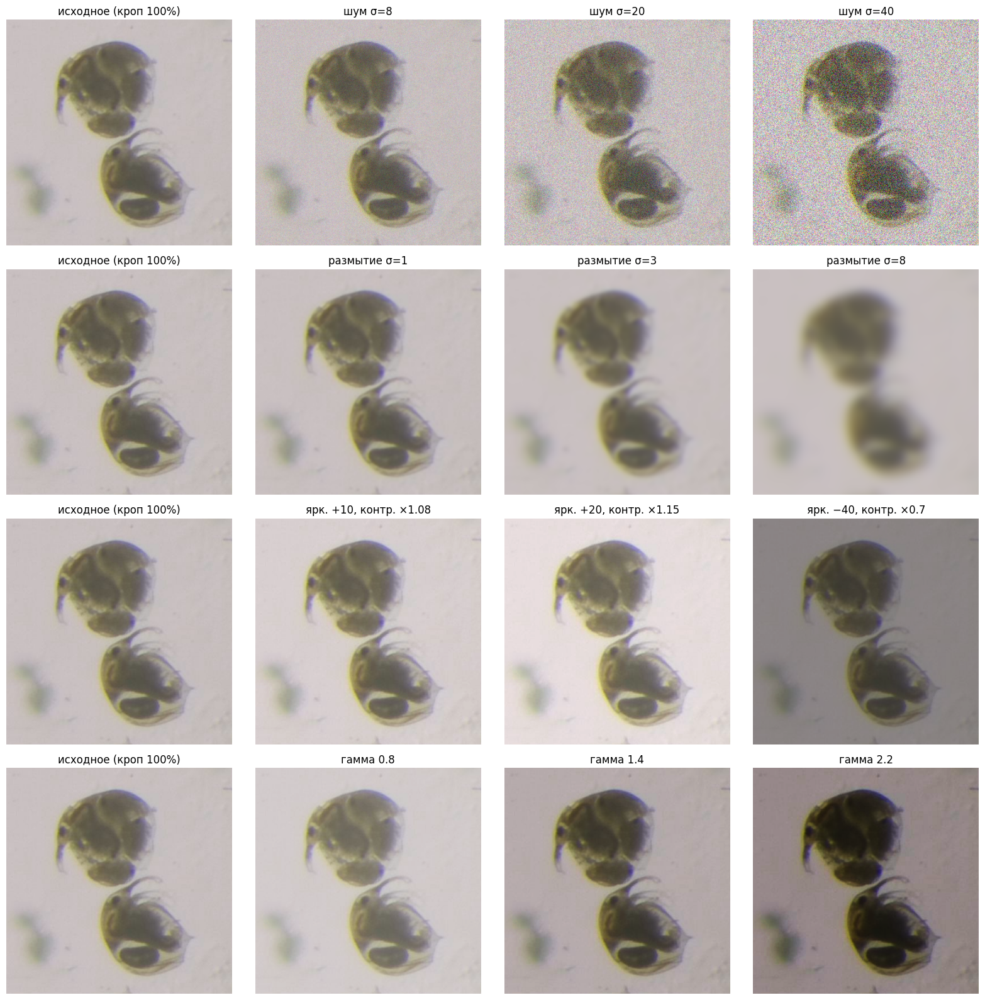

In [8]:
# Кропы 100%: на уменьшенной картинке шум/размытие не видны. Центр - самый крупный оценённый объект.
bl = BLOBS_BY_FILE.get(DEMO_IMAGE, [])

if bl:
    b0 = max(bl, key=lambda c: c['area_px'])
else:
    b0 = {'x1': 0, 'y1': 0, 'x2': demo.shape[1], 'y2': demo.shape[0]}

cx = int((b0['x1'] + b0['x2']) / 2)
cy = int((b0['y1'] + b0['y2']) / 2)
R = 200

y0 = max(0, min(demo.shape[0] - 2 * R, cy - R))
x0 = max(0, min(demo.shape[1] - 2 * R, cx - R))

rows = [
    ('шум', ['noise_weak', 'noise_medium', 'noise_strong']),
    ('размытие', ['blur_weak', 'blur_medium', 'blur_strong']),
    ('яркость/контраст', ['bc_weak', 'bc_medium', 'bc_strong']),
    ('гамма', ['gamma_weak', 'gamma_medium', 'gamma_strong']),
]

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

for r, (title, names) in enumerate(rows):
    axes[r, 0].imshow(demo[y0:y0 + 2 * R, x0:x0 + 2 * R])
    axes[r, 0].set_title('исходное (кроп 100%)')

    for c, n in enumerate(names, 1):
        augmented = apply_aug(demo, n, DEMO_IMAGE)
        axes[r, c].imshow(augmented[y0:y0 + 2 * R, x0:x0 + 2 * R])
        axes[r, c].set_title(AUG_BY_NAME[n]['label'])

for ax in axes.ravel():
    ax.axis('off')

plt.tight_layout()
fig.savefig(AUG_DIR / 'augmentation_levels_crops.png', dpi=90)
plt.show()

In [9]:
# Количественно: насколько аугментация портит детали (5 кадров, полное разрешение).

def psnr(a, b):
    diff = a.astype(np.float32) - b.astype(np.float32)
    mse = np.mean(diff ** 2)

    if mse > 0:
        return float(10 * np.log10(255 ** 2 / mse))
    return np.inf


def lapv(im):
    gray = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())


n_samples = min(5, len(stats_df))
sample_idx = np.linspace(0, len(stats_df) - 1, n_samples).astype(int)
sample = [PATH_BY_NAME[f] for f in stats_df.file.iloc[sample_idx]]
geometric_kinds = ('rotate90', 'flip', 'rotate', 'scale')

q = []
for p in sample:
    o = load_rgb(p)
    lo = lapv(o)
    so = float(o.std())

    for a in AUGMENTATIONS:
        x = apply_aug(o, a['name'], p.name)
        same = x.shape == o.shape and a['kind'] not in geometric_kinds

        q.append({
            'aug': a['name'],
            'group': a['group'],
            'psnr_db': psnr(o, x) if same else np.nan,
            'laplacian_var_ratio': lapv(x) / lo,
            'std_ratio': float(x.std()) / so,
            'mean_shift': float(x.mean() - o.mean()),
        })

aug_quality = pd.DataFrame(q).groupby(['group', 'aug'], sort=False)
aug_quality = aug_quality.mean(numeric_only=True).round(3)
aug_quality.to_csv(TABLE_DIR / 'augmentation_quality.csv')
display(aug_quality)

psnr_db  laplacian_var_ratio  std_ratio  \
group            aug                                                     
яркость/контраст bc_weak        26.040                1.249      1.080   
                 bc_medium      20.012                1.423      1.150   
                 bc_strong      13.741                0.626      0.700   
шум              noise_weak     30.049              107.461      1.086   
                 noise_medium   22.132              662.873      1.432   
                 noise_strong   16.426             2465.232      2.161   
размытие         blur_weak      50.345                0.316      0.997   
                 blur_medium    43.314                0.126      0.989   
                 blur_strong    38.089                0.082      0.968   
гамма            gamma_weak     25.822                0.890      0.918   
                 gamma_medium   20.566                1.503      1.085   
                 gamma_strong   12.602                2.003      1.078   
геометрия        rot90             NaN                1.000      1.000   
                 rot15             NaN                0.659      0.982   
                 flip_h            NaN                1.000      1.000   
                 flip_v            NaN                1.000      1.000   
                 scale_0.8         NaN                0.713      0.822   
                 scale_1.25        NaN                0.523      1.140   

                               mean_shift  
group            aug                       
яркость/контраст bc_weak           12.664  
                 bc_medium         25.383  
                 bc_strong        -52.275  
шум              noise_weak        -0.500  
                 noise_medium      -0.469  
                 noise_strong      -0.864  
размытие         blur_weak         -0.000  
                 blur_medium       -0.000  
                 blur_strong       -0.000  
гамма            gamma_weak        13.011  
                 gamma_medium     -23.744  
                 gamma_strong     -59.200  
геометрия        rot90              0.000  
                 rot15              0.182  
                 flip_h             0.000  
                 flip_v             0.000  
                 scale_0.8          2.848  
                 scale_1.25        -4.457

### 1.3 Какие аугментации допустимы

Таблица выше: `psnr_db` - отклонение от исходника; `laplacian_var_ratio` - сохранность мелких деталей/краёв (<1 - детали потеряны; >1 у шума - ложная «резкость» от шума); `std_ratio` - изменение контраста.

**Допустимы (не меняют морфологию):**

- Отражения и повороты на 90° (у микроскопического кадра нет верха или низа, ориентация организма не несёт смысла, как и образец может быть положен разными сторонами);
- Умеренные яркость/контраст и гамма (вариации освещения/экспозиции)
- Слабый шум σ≈8 (как шум сенсора);
- Слабое размытие σ≈1 (небольшая расфокусировка);
- Масштаб (есть фото в разном увеличении)

**Условно допустимы:**

- Поворот на произвольный угол (нужна заливка фоном);
- Средний шум σ≈20 и размытие σ≈3.

**Недопустимы:**
- сильное размытие (σ=8 и более) стирает щетинки, антенны, контур панциря, и другие ключевые признаки;
- сильный шум σ>40 маскирует полупрозрачные границы и создаёт артефакты;
- сильное снижение контраста (×0.7, −40) сливает прозрачные части с фоном;
- сильная гамма смещает видимость полупрозрачных структур.

Цветовые/тоновые преобразования (hue/saturation) не применяю: окраска (бурый пигмент) - признак.

## 2. Детекция объектов
### 2.1 Выбор моделей

| | **YOLOv8n** (одноэтапная) | **Faster R-CNN R50-FPN** (двухэтапная) |
|---|---|---|
| Принцип | один проход: сеть сразу предсказывает рамки и классы на сетке признаков | 1) RPN предлагает регионы-кандидаты, 2) RoIAlign вырезает признаки региона, голова классифицирует и уточняет рамку |
| Архитектура | CSPDarknet-backbone + PAN-neck, anchor-free decoupled head | ResNet-50 + FPN, RPN, RoI-голова (2 FC) |
| Вход | letterbox до `imgsz` (здесь 1024) | ресайз до ~800-1333 px по сторонам |
| Постобработка | NMS | NMS (по классам; здесь добавлен класс-независимый NMS) |
| Параметры / FLOPs | ≈3.2 М / ≈8.7 G | ≈41.8 М / ≈134 G |
| COCO box AP | ≈37.3 | ≈37.0 |

Обе модели - канонические представители парадигм, обе доступны сразу с весами COCO, и при **сопоставимом COCO-AP (~37)** различаются по скорости и размеру на порядок - значит, сравнение выявляет именно эффект архитектуры (скорость против тщательности), а не разницу в «силе» моделей. Для справедливости: одинаковые порог (0.15), NMS IoU (0.5, класс-независимый), максимум 100 рамок, сопоставимый масштаб входа, одинаковые изображения и аугментации, время измеряется «numpy-кадр -> рамки» с синхронизацией GPU и прогревом.

Классы COCO («bird», «person», итд) для планктона бессмысленны, поэтому детекторы использую **класс-независимо** (рамка = «какой-то объект»); распределение выданных классов показано ниже как демонстрация доменного сдвига.

In [10]:
import torchvision
import torchvision.transforms.functional as TF
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights,
)
from ultralytics import YOLO


yolo_model = YOLO(YOLO_WEIGHTS)

frcnn_weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
frcnn_model = fasterrcnn_resnet50_fpn(
    weights=frcnn_weights,
    box_score_thresh=DET_CONF_STORE,
    box_nms_thresh=DET_NMS_IOU,
    box_detections_per_img=DET_MAX,
)
frcnn_model = frcnn_model.to(DEVICE).eval()

COCO_CATEGORIES = frcnn_weights.meta['categories']
print('Модели загружены на', DEVICE)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 122MB/s]


Модели загружены на cuda


In [11]:
def _sync():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()


def detect_yolo(rgb):
    # ultralytics ожидает BGR для numpy-массивов
    bgr = np.ascontiguousarray(rgb[..., ::-1])

    _sync()
    t0 = time.perf_counter()
    res = yolo_model.predict(
        source=bgr,
        conf=DET_CONF_STORE,
        iou=DET_NMS_IOU,
        imgsz=YOLO_IMGSZ,
        agnostic_nms=True,
        max_det=DET_MAX,
        verbose=False,
    )[0]
    _sync()
    elapsed = time.perf_counter() - t0

    rows = []
    for b in res.boxes:
        x1, y1, x2, y2 = b.xyxy[0].cpu().numpy().tolist()
        class_id = int(b.cls[0].item())

        rows.append({
            'x1': x1,
            'y1': y1,
            'x2': x2,
            'y2': y2,
            'score': float(b.conf[0].item()),
            'class_id': class_id,
            'label': yolo_model.names.get(class_id, str(class_id)),
        })

    return rows, elapsed


def detect_frcnn(rgb):
    _sync()
    t0 = time.perf_counter()
    tensor = TF.to_tensor(rgb).to(DEVICE)

    with torch.inference_mode():
        pred = frcnn_model([tensor])[0]
        # класс-независимый NMS
        keep = torchvision.ops.nms(pred['boxes'], pred['scores'], DET_NMS_IOU)

    _sync()
    elapsed = time.perf_counter() - t0

    rows = []
    for i in keep.cpu().numpy():
        x1, y1, x2, y2 = pred['boxes'][i].cpu().numpy().tolist()
        class_id = int(pred['labels'][i])

        rows.append({
            'x1': x1,
            'y1': y1,
            'x2': x2,
            'y2': y2,
            'score': float(pred['scores'][i]),
            'class_id': class_id,
            'label': COCO_CATEGORIES[class_id],
        })

    return rows, elapsed

### 2.2 Применение и визуализация
Рамки рисуются с классом COCO и confidence. Панели 2×2 (строки - детекторы, столбцы - оригинал / `PRIMARY_AUG`) сохраняются для каждого изображения в `results/detections/`.

In [12]:
DET_COLORS = {'YOLOv8n': (255, 140, 0), 'FasterRCNN': (30, 144, 255)}
FONT = cv2.FONT_HERSHEY_SIMPLEX


def draw_dets(rgb, rows, color, max_side=800, thr=None, label=True):
    h, w = rgb.shape[:2]
    sc = max_side / max(h, w)

    resized = cv2.resize(rgb, (int(w * sc), int(h * sc)), interpolation=cv2.INTER_AREA)
    img = resized.copy()

    for r in rows:
        if thr is not None and r['score'] < thr:
            continue

        p1 = (int(r['x1'] * sc), int(r['y1'] * sc))
        p2 = (int(r['x2'] * sc), int(r['y2'] * sc))
        cv2.rectangle(img, p1, p2, color, 2)

        if label:
            txt = f"{r['label']} {r['score']:.2f}"
            (tw, th), _ = cv2.getTextSize(txt, FONT, 0.5, 1)
            y0 = max(p1[1], th + 4)

            cv2.rectangle(img, (p1[0], y0 - th - 4), (p1[0] + tw + 2, y0), color, -1)
            cv2.putText(img, txt, (p1[0] + 1, y0 - 3), FONT, 0.5, (0, 0, 0), 1, cv2.LINE_AA)

    return img


def add_title(img, text):
    bar = np.full((28, img.shape[1], 3), 255, np.uint8)
    cv2.putText(bar, text, (6, 20), FONT, 0.6, (0, 0, 0), 1, cv2.LINE_AA)
    return np.vstack([bar, img])

### 2.3 Четыре группы экспериментов
| № | Архитектура | Данные |
|---|---|---|
| 1 | YOLOv8n | исходные |
| 2 | YOLOv8n | аугментированные (`DET_AUG_NAMES`: по одному уровню каждого типа + сильный шум и размытие + 90° и отражение) |
| 3 | Faster R-CNN | исходные |
| 4 | Faster R-CNN | аугментированные (те же) |

Одни и те же 50 исходных изображений и одни и те же аугментации (детерминированные). Рамки с аугментированных кадров возвращаются в систему координат оригинала для сравнения. Результаты сохраняются в `detections.csv/json` (все рамки с score ≥ 0.05, флаг `passes_threshold` для основного порога) и `detection_runs.csv` (включая запуски без детекций).

In [13]:
DETECTORS = {'YOLOv8n': detect_yolo, 'FasterRCNN': detect_frcnn}
EXP_ID = {
    ('YOLOv8n', 'original'): 1,
    ('YOLOv8n', 'augmented'): 2,
    ('FasterRCNN', 'original'): 3,
    ('FasterRCNN', 'augmented'): 4,
}
IMG_HW = {r.file: (int(r.height), int(r.width)) for r in stats_df.itertuples()}
# (image, detector, aug_name) -> рамки (score>=DET_CONF_STORE), координаты в кадре входа и в оригинале (_o)
DET_STORE = {}
det_rows = []
run_rows = []

warmup_image = load_rgb(paths_for_exp[0])
# прогрев (CUDA, cudnn, инициализация) - не входит в замеры
for _ in range(3):
    for detect_fn in DETECTORS.values():
        detect_fn(warmup_image)

variants = [('original', 'original')]
variants += [('augmented', a) for a in DET_AUG_NAMES]

for idx, p in enumerate(paths_for_exp):
    rgb = load_rgb(p)
    H, W = rgb.shape[:2]
    keep_imgs = {}

    for variant, aug in variants:
        x = rgb if aug == 'original' else apply_aug(rgb, aug, p.name)

        if aug in ('original', PRIMARY_AUG):
            keep_imgs[aug] = x

        for det_name, detect_fn in DETECTORS.items():
            rows, elapsed = detect_fn(x)
            exp_id = EXP_ID[(det_name, variant)]
            out = []

            sorted_rows = sorted(rows, key=lambda item: -item['score'])
            for rank, r in enumerate(sorted_rows):
                xo = box_to_original((r['x1'], r['y1'], r['x2'], r['y2']), aug, (H, W))
                box_area = (r['x2'] - r['x1']) * (r['y2'] - r['y1'])

                out.append({
                    'exp_id': exp_id,
                    'detector': det_name,
                    'data_variant': variant,
                    'aug_name': aug,
                    'image': p.name,
                    'det_idx': rank,
                    **r,
                    'x1_o': xo[0],
                    'y1_o': xo[1],
                    'x2_o': xo[2],
                    'y2_o': xo[3],
                    'box_area_frac': box_area / (x.shape[0] * x.shape[1]),
                    'passes_threshold': r['score'] >= DET_CONF,
                })

            DET_STORE[(p.name, det_name, aug)] = out
            det_rows += out

            run_rows.append({
                'exp_id': exp_id,
                'detector': det_name,
                'data_variant': variant,
                'aug_name': aug,
                'image': p.name,
                'n_det': sum(o['passes_threshold'] for o in out),
                'n_det_store': len(out),
                'seconds': elapsed,
                'device': DEVICE,
            })

    tiles = []

    for det_name in DETECTORS:
        row_tiles = []

        for panel_aug in ('original', PRIMARY_AUG):
            stored = DET_STORE[(p.name, det_name, panel_aug)]
            passed = [o for o in stored if o['passes_threshold']]
            drawn = draw_dets(keep_imgs[panel_aug], passed, DET_COLORS[det_name], 800)
            title = f'{det_name} | {panel_aug} | n={len(passed)}'
            row_tiles.append(add_title(drawn, title))

        tiles.append(np.hstack(row_tiles))

    panel = np.vstack(tiles)
    panel_path = DET_DIR / f'{p.stem}__detections.jpg'
    cv2.imwrite(
        str(panel_path),
        cv2.cvtColor(panel, cv2.COLOR_RGB2BGR),
        [cv2.IMWRITE_JPEG_QUALITY, 85],
    )

    if (idx + 1) % 10 == 0:
        print(f'  обработано {idx + 1}/{len(paths_for_exp)}')


dets_df = pd.DataFrame(det_rows)
runs_df = pd.DataFrame(run_rows)
dets_df.to_csv(TABLE_DIR / 'detections.csv', index=False)
runs_df.to_csv(TABLE_DIR / 'detection_runs.csv', index=False)

det_config = {}
for key in RUN_CONFIG:
    if key.startswith(('DET_', 'YOLO_', 'STAB')):
        det_config[key] = RUN_CONFIG[key]

payload = {
    'config': det_config,
    'environment': ENV,
    'detections': dets_df.round(4).to_dict('records'),
}
(TABLE_DIR / 'detections.json').write_text(json.dumps(payload, ensure_ascii=False))

dets_main = dets_df[dets_df.passes_threshold]
print(f'Запусков: {len(runs_df)}, рамок (score>={DET_CONF}): {len(dets_main)}')

  обработано 10/50
  обработано 20/50
  обработано 30/50
  обработано 40/50
  обработано 50/50
Запусков: 900, рамок (score>=0.15): 3779


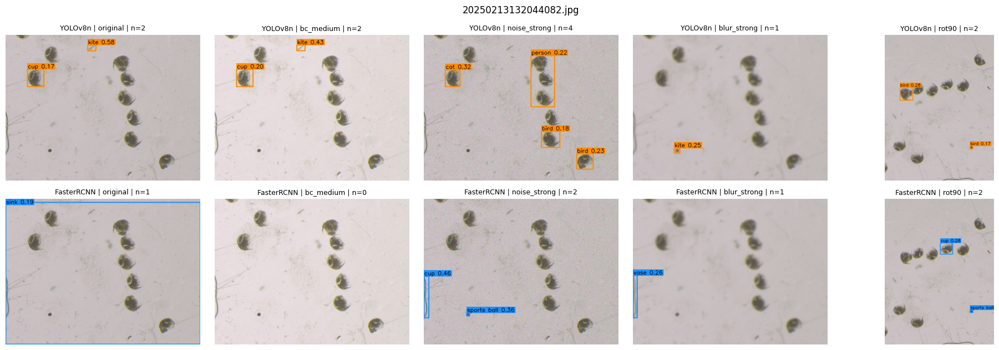

In [14]:
def show_det_grid(image_name, aug_names, max_side=520):
    rgb = load_rgb(PATH_BY_NAME[image_name])
    cols = ['original'] + list(aug_names)

    fig, axes = plt.subplots(
        len(DETECTORS), len(cols),
        figsize=(3.8 * len(cols), 3.2 * len(DETECTORS)),
        squeeze=False,
    )

    for r, det in enumerate(DETECTORS):
        for c, a in enumerate(cols):
            x = rgb if a == 'original' else apply_aug(rgb, a, image_name)
            stored = DET_STORE[(image_name, det, a)]
            rows = [o for o in stored if o['passes_threshold']]

            axes[r, c].imshow(draw_dets(x, rows, DET_COLORS[det], max_side))
            axes[r, c].axis('off')
            axes[r, c].set_title(f'{det} | {a} | n={len(rows)}', fontsize=9)

    plt.suptitle(image_name)
    plt.tight_layout()
    plt.show()


show_det_grid(DEMO_IMAGE, ['bc_medium', 'noise_strong', 'blur_strong', 'rot90'])

### 2.4 Сравнение результатов

In [15]:
def summarize(runs, dets, keys):
    out = []

    for key, g in runs.groupby(keys):
        key = key if isinstance(key, tuple) else (key,)

        d = dets
        for key_name, key_value in zip(keys, key):
            d = d[d[key_name] == key_value]

        has_dets = len(d) > 0
        summary = dict(zip(keys, key))

        summary.update({
            'n_runs': len(g),
            'n_images': g.image.nunique(),
            'total_detections': int(g.n_det.sum()),
            'mean_det_per_run': g.n_det.mean(),
            'std_det_per_run': g.n_det.std(),
            'runs_with_detections': int((g.n_det > 0).sum()),
            'share_runs_with_detections': (g.n_det > 0).mean(),
            'mean_ms': 1000 * g.seconds.mean(),
            'median_ms': 1000 * g.seconds.median(),
            'mean_score': d.score.mean() if has_dets else np.nan,
            'median_box_area_frac': d.box_area_frac.median() if has_dets else np.nan,
        })
        out.append(summary)

    return pd.DataFrame(out)


det_summary = summarize(runs_df, dets_main, ['exp_id', 'detector', 'data_variant'])
det_summary_by_aug = summarize(runs_df, dets_main, ['detector', 'aug_name'])

det_summary.to_csv(TABLE_DIR / 'detection_summary.csv', index=False)
det_summary_by_aug.to_csv(TABLE_DIR / 'detection_summary_by_aug.csv', index=False)

display(det_summary.round(3))
display(det_summary_by_aug.round(3))

,exp_id,detector,data_variant,n_runs,n_images,total_detections,mean_det_per_run,std_det_per_run,runs_with_detections,share_runs_with_detections,mean_ms,median_ms,mean_score,median_box_area_frac
0,1,YOLOv8n,original,50,50,363,7.260,6.791,48,0.960,14.533,13.437,0.281,0.001
1,2,YOLOv8n,augmented,400,50,1910,4.775,5.468,358,0.895,13.482,12.584,0.285,0.001
2,3,FasterRCNN,original,50,50,180,3.600,2.138,49,0.980,157.868,157.013,0.437,0.029
3,4,FasterRCNN,augmented,400,50,1326,3.315,2.045,381,0.952,156.697,156.215,0.457,0.027


,detector,aug_name,n_runs,n_images,total_detections,mean_det_per_run,std_det_per_run,runs_with_detections,share_runs_with_detections,mean_ms,median_ms,mean_score,median_box_area_frac
0,FasterRCNN,bc_medium,50,50,190,3.80,2.129,48,0.96,157.304,157.266,0.434,0.025
1,FasterRCNN,blur_medium,50,50,201,4.02,2.378,49,0.98,156.656,156.187,0.450,0.016
2,FasterRCNN,blur_strong,50,50,120,2.40,1.355,47,0.94,156.122,155.635,0.454,0.050
3,FasterRCNN,flip_h,50,50,162,3.24,1.721,48,0.96,156.613,156.813,0.461,0.029
4,FasterRCNN,gamma_medium,50,50,159,3.18,1.600,49,0.98,155.916,155.555,0.481,0.037
5,FasterRCNN,noise_medium,50,50,142,2.84,1.777,46,0.92,157.112,155.892,0.464,0.022
6,FasterRCNN,noise_strong,50,50,157,3.14,2.356,47,0.94,156.521,155.609,0.461,0.020
7,FasterRCNN,original,50,50,180,3.60,2.138,49,0.98,157.868,157.013,0.437,0.029
8,FasterRCNN,rot90,50,50,195,3.90,2.358,47,0.94,157.332,157.031,0.455,0.018
9,YOLOv8n,bc_medium,50,50,208,4.16,3.460,44,0.88,13.062,12.304,0.290,0.001


In [16]:
# Устойчивость рамок: сопоставление «оригинал - аугментация» венгерским алгоритмом по IoU (рамки аугментации - в системе координат оригинала).
from scipy.optimize import linear_sum_assignment


def iou_matrix(A, B):
    A = np.array(A, float)[:, None, :]
    B = np.array(B, float)[None, :, :]

    inter_w = np.minimum(A[..., 2], B[..., 2]) - np.maximum(A[..., 0], B[..., 0])
    inter_h = np.minimum(A[..., 3], B[..., 3]) - np.maximum(A[..., 1], B[..., 1])
    inter = np.clip(inter_w, 0, None) * np.clip(inter_h, 0, None)

    area_a = (A[..., 2] - A[..., 0]) * (A[..., 3] - A[..., 1])
    area_b = (B[..., 2] - B[..., 0]) * (B[..., 3] - B[..., 1])

    return inter / np.maximum(area_a + area_b - inter, 1e-9)


def match_boxes(a, b, thr):
    if not a or not b:
        return []

    M = iou_matrix(a, b)
    rows, cols = linear_sum_assignment(-M)

    matches = []
    for i, j in zip(rows, cols):
        if M[i, j] >= thr:
            matches.append((i, j, M[i, j]))

    return matches


def main(key):
    return [r for r in DET_STORE[key] if r['passes_threshold']]


st = []

for p in paths_for_exp:
    for det in DETECTORS:
        base = main((p.name, det, 'original'))
        base_boxes = [[r['x1'], r['y1'], r['x2'], r['y2']] for r in base]

        for aug in DET_AUG_NAMES:
            ag = main((p.name, det, aug))
            aug_boxes = [[r['x1_o'], r['y1_o'], r['x2_o'], r['y2_o']] for r in ag]
            m = match_boxes(base_boxes, aug_boxes, STABILITY_IOU)

            sum_iou = float(sum(x[2] for x in m))
            sum_dscore = sum(abs(base[i]['score'] - ag[j]['score']) for i, j, _ in m)

            st.append({
                'detector': det,
                'aug_name': aug,
                'image': p.name,
                'n_orig': len(base),
                'n_aug': len(ag),
                'n_match': len(m),
                'sum_iou': sum_iou,
                'sum_dscore': float(sum_dscore),
            })

stab = pd.DataFrame(st)
stab.to_csv(TABLE_DIR / 'detection_stability_per_image.csv', index=False)


def agg(g):
    n_orig = g.n_orig.sum()
    n_aug = g.n_aug.sum()
    n_match = g.n_match.sum()

    return pd.Series({
        'n_orig': n_orig,
        'n_aug': n_aug,
        'count_ratio': n_aug / max(n_orig, 1),
        'kept_rate': n_match / max(n_orig, 1),
        'new_rate': 1 - n_match / max(n_aug, 1),
        'mean_iou_matched': g.sum_iou.sum() / max(n_match, 1),
        'mean_abs_dscore': g.sum_dscore.sum() / max(n_match, 1),
    })


stab_by_aug = stab.groupby(['detector', 'aug_name'], sort=False)
stab_by_aug = stab_by_aug.apply(agg, include_groups=False).round(3)

stab_overall = stab.groupby('detector')
stab_overall = stab_overall.apply(agg, include_groups=False).round(3)

stab_by_aug.to_csv(TABLE_DIR / 'detection_stability.csv')
stab_overall.to_csv(TABLE_DIR / 'detection_stability_overall.csv')

display(stab_by_aug)
display(stab_overall)

md_note = "`kept_rate` - доля рамок оригинала, найденных на аугментации с IoU≥%.1f; `new_rate` - доля «новых» рамок аугментации; `mean_iou_matched` - смещение рамок."
display(Markdown(md_note))

n_orig  n_aug  count_ratio  kept_rate  new_rate  \
detector   aug_name                                                        
YOLOv8n    bc_medium      363.0  208.0        0.573      0.559     0.024   
           noise_medium   363.0  106.0        0.292      0.157     0.462   
           noise_strong   363.0  128.0        0.353      0.118     0.664   
           blur_medium    363.0  339.0        0.934      0.730     0.218   
           blur_strong    363.0   50.0        0.138      0.069     0.500   
           gamma_medium   363.0  276.0        0.760      0.702     0.076   
           rot90          363.0  443.0        1.220      0.642     0.474   
           flip_h         363.0  360.0        0.992      0.722     0.272   
FasterRCNN bc_medium      180.0  190.0        1.056      0.889     0.158   
           noise_medium   180.0  142.0        0.789      0.467     0.408   
           noise_strong   180.0  157.0        0.872      0.406     0.535   
           blur_medium    180.0  201.0        1.117      0.778     0.303   
           blur_strong    180.0  120.0        0.667      0.478     0.283   
           gamma_medium   180.0  159.0        0.883      0.794     0.101   
           rot90          180.0  195.0        1.083      0.572     0.472   
           flip_h         180.0  162.0        0.900      0.700     0.222   

                         mean_iou_matched  mean_abs_dscore  
detector   aug_name                                         
YOLOv8n    bc_medium                0.960            0.064  
           noise_medium             0.917            0.138  
           noise_strong             0.888            0.150  
           blur_medium              0.889            0.063  
           blur_strong              0.832            0.153  
           gamma_medium             0.960            0.060  
           rot90                    0.862            0.111  
           flip_h                   0.892            0.078  
FasterRCNN bc_medium                0.949            0.066  
           noise_medium             0.873            0.192  
           noise_strong             0.866            0.198  
           blur_medium              0.909            0.157  
           blur_strong              0.873            0.220  
           gamma_medium             0.955            0.091  
           rot90                    0.863            0.236  
           flip_h                   0.905            0.126

,n_orig,n_aug,count_ratio,kept_rate,new_rate,mean_iou_matched,mean_abs_dscore
detector,,,,,,,
FasterRCNN,1440.0,1326.0,0.921,0.635,0.310,0.907,0.148
YOLOv8n,2904.0,1910.0,0.658,0.462,0.297,0.909,0.082


`kept_rate` — доля рамок оригинала, найденных на аугментации с IoU≥0.5; `new_rate` — доля «новых» рамок аугментации; `mean_iou_matched` — смещение рамок.

In [17]:
# Чувствительность к порогу и «семантика» классов COCO.
sens = []

for det in DETECTORS:
    is_det = dets_df.detector == det
    is_original = dets_df.aug_name == 'original'
    d0 = dets_df[is_det & is_original]

    for thr in [0.05, 0.15, 0.30, 0.50]:
        counts = d0[d0.score >= thr].groupby('image').size()
        counts = counts.reindex(list(PATH_BY_NAME), fill_value=0)

        sens.append({
            'detector': det,
            'threshold': thr,
            'mean_det_per_image': counts.mean(),
            'images_with_detections': int((counts > 0).sum()),
        })

sens = pd.DataFrame(sens)
sens.to_csv(TABLE_DIR / 'detection_threshold_sensitivity.csv', index=False)
display(sens.round(3))

original_main = dets_main[dets_main.aug_name == 'original']
cls = original_main.groupby(['detector', 'label']).size()
cls = cls.rename('n').reset_index()
cls = cls.sort_values(['detector', 'n'], ascending=[True, False])
cls = cls.groupby('detector').head(6)

display(cls)

,detector,threshold,mean_det_per_image,images_with_detections
0,YOLOv8n,0.05,18.98,50
1,YOLOv8n,0.15,7.26,48
2,YOLOv8n,0.30,2.36,42
3,YOLOv8n,0.50,0.72,22
4,FasterRCNN,0.05,5.86,50
5,FasterRCNN,0.15,3.60,49
6,FasterRCNN,0.30,2.06,43
7,FasterRCNN,0.50,1.30,36


,detector,label,n
9,FasterRCNN,kite,49
1,FasterRCNN,bird,43
6,FasterRCNN,dining table,17
12,FasterRCNN,sink,12
4,FasterRCNN,cake,11
8,FasterRCNN,donut,9
24,YOLOv8n,kite,291
22,YOLOv8n,cup,26
19,YOLOv8n,bird,22
20,YOLOv8n,bowl,5


**Ложные срабатывания и пропуски.** Эталонной разметки нет, поэтому использую эвристический прокси из п. 1.1: «кандидат в ложное срабатывание» - рамка, внутри которой почти нет «тёмного объекта» (покрытие < 10 %) или которая занимает > 50 % кадра; «кандидат в пропуск» - оценённый объект, центр которого не попал ни в одну рамку. Прокси грубый (нити/пыль считаются блобами => пропуски завышаются; полупрозрачные организмы дают низкое покрытие => ложные срабатывания завышаются), поэтому флагнутые случаи просмотрю глазами ниже.

,detector,boxes,fp_candidates,fp_candidate_share,blobs_total,blobs_not_covered,miss_candidate_share
0,YOLOv8n,363,264,0.727,458,306,0.668
1,FasterRCNN,180,86,0.478,458,54,0.118


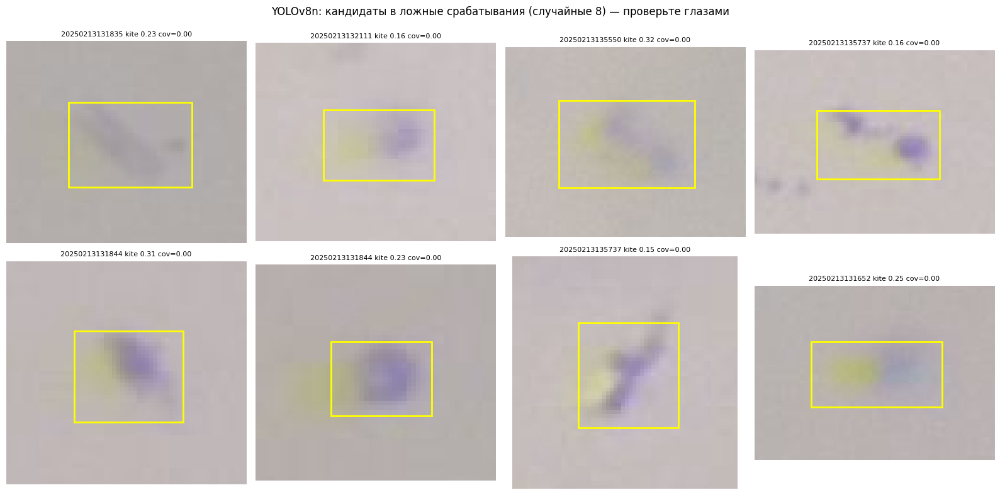

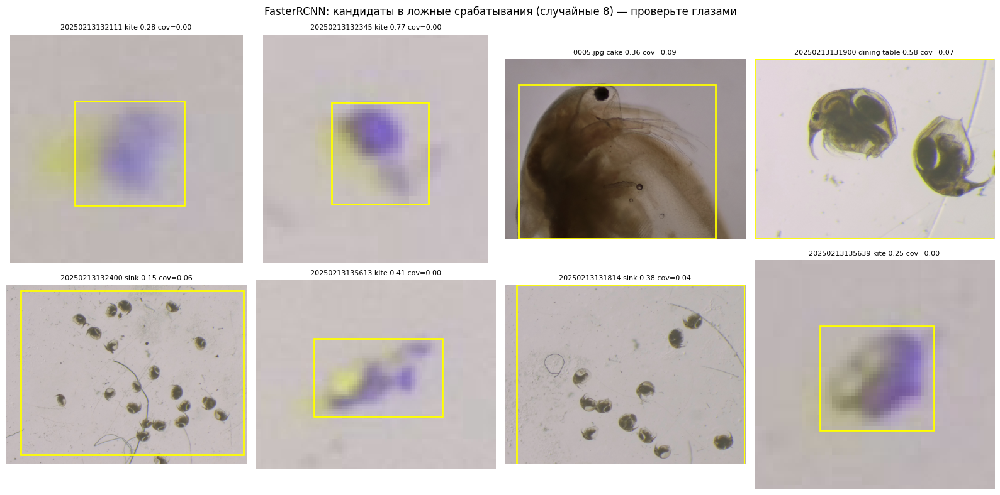

In [18]:
def proxy_check(rows, image):
    fg, s = FG_CACHE[image]
    hh, ww = fg.shape
    flags = []

    for r in rows:
        x1 = int(r['x1'] * s)
        y1 = int(r['y1'] * s)
        x2 = max(int(r['x2'] * s), x1 + 1)
        y2 = max(int(r['y2'] * s), y1 + 1)

        if y2 > 0 and x2 > 0:
            region = fg[max(0, y1):min(hh, y2), max(0, x1):min(ww, x2)]
            coverage = float(region.mean())
        else:
            coverage = 0.0

        is_fp = coverage < 0.10 or r['box_area_frac'] > 0.5
        flags.append({**r, 'proxy_coverage': coverage, 'fp_candidate': is_fp})

    return flags


def missed_blobs(rows, image):
    out = []

    for c in BLOBS_BY_FILE.get(image, []):
        cx = (c['x1'] + c['x2']) / 2
        cy = (c['y1'] + c['y2']) / 2

        covered = any(
            r['x1'] <= cx <= r['x2'] and r['y1'] <= cy <= r['y2']
            for r in rows
        )
        if not covered:
            out.append(c)

    return out


prx = []
FP_CASES = []
MISS_CASES = []

for det in DETECTORS:
    n_boxes = 0
    n_fp = 0
    n_missed = 0
    n_blobs = 0

    for name in PATH_BY_NAME:
        rows = main((name, det, 'original'))
        flagged = proxy_check(rows, name)
        missed = missed_blobs(rows, name)

        n_boxes += len(flagged)
        n_fp += sum(f['fp_candidate'] for f in flagged)
        n_blobs += len(BLOBS_BY_FILE.get(name, []))
        n_missed += len(missed)

        FP_CASES += [(det, name, f) for f in flagged if f['fp_candidate']]
        MISS_CASES.append((det, name, len(missed)))

    prx.append({
        'detector': det,
        'boxes': n_boxes,
        'fp_candidates': n_fp,
        'fp_candidate_share': n_fp / max(n_boxes, 1),
        'blobs_total': n_blobs,
        'blobs_not_covered': n_missed,
        'miss_candidate_share': n_missed / max(n_blobs, 1),
    })

prx = pd.DataFrame(prx)
prx.to_csv(TABLE_DIR / 'detection_proxy_check.csv', index=False)
display(prx.round(3))


def crop_gallery(items, ncols=4, title='', pad=0.25, fname=None):
    # items: (image, box dict, caption)
    n = len(items)

    if n == 0:
        print('нет случаев')
        return

    n_rows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(
        n_rows, ncols,
        figsize=(4 * ncols, 4 * np.ceil(n / ncols)),
        squeeze=False,
    )

    for ax, (name, b, cap) in zip(axes.ravel(), items):
        rgb = load_rgb(PATH_BY_NAME[name])
        H, W = rgb.shape[:2]
        bw = b['x2'] - b['x1']
        bh = b['y2'] - b['y1']

        m = int(pad * max(bw, bh)) + 10
        X1 = max(0, int(b['x1']) - m)
        Y1 = max(0, int(b['y1']) - m)
        X2 = min(W, int(b['x2']) + m)
        Y2 = min(H, int(b['y2']) + m)

        ax.imshow(rgb[Y1:Y2, X1:X2])
        rect = plt.Rectangle((b['x1'] - X1, b['y1'] - Y1), bw, bh, fill=False, ec='yellow', lw=2)
        ax.add_patch(rect)
        ax.set_title(cap, fontsize=8)

    for ax in axes.ravel():
        ax.axis('off')

    plt.suptitle(title)
    plt.tight_layout()

    if fname:
        plt.savefig(ANALYSIS_DIR / fname, dpi=90)

    plt.show()


rng = np.random.default_rng(SEED)

for det in DETECTORS:
    cases = [c for c in FP_CASES if c[0] == det]
    cases = [cases[i] for i in rng.permutation(len(cases))[:8]]

    items = []
    for _, name, f in cases:
        caption = f"{name[:14]} {f['label']} {f['score']:.2f} cov={f['proxy_coverage']:.2f}"
        items.append((name, f, caption))

    crop_gallery(
        items,
        title=f'{det}: кандидаты в ложные срабатывания (случайные 8)',
        fname=f'fp_candidates_{det}.png',
    )

Здесь неверно обнаружены ложные срабатывания только у FasterRCNN - хотя и вправду эти рамки не обозначают каждая отдельный организм (кроме 0005.jpg).

YOLOv8n: 20250213135232524.jpg — не покрыто блобов: 20


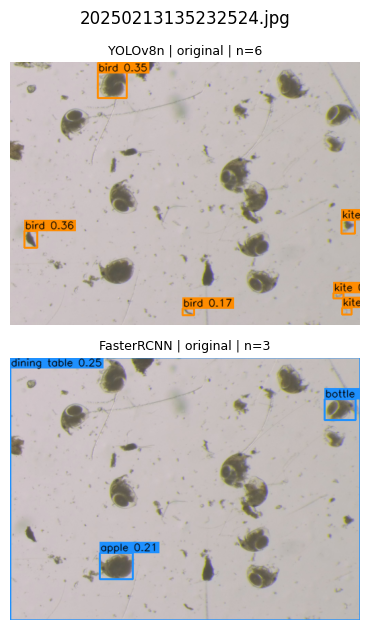

YOLOv8n: 20250213135439391.jpg — не покрыто блобов: 18


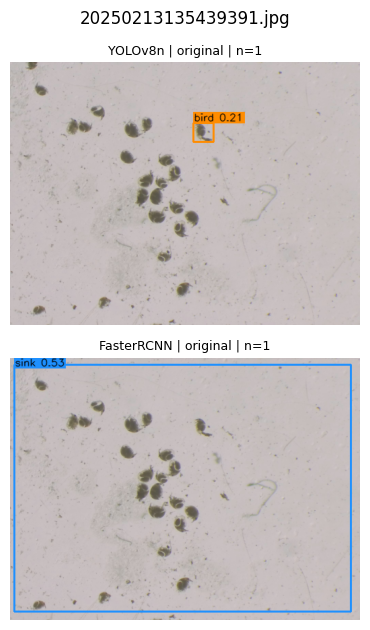

FasterRCNN: 20250213135256554.jpg — не покрыто блобов: 14


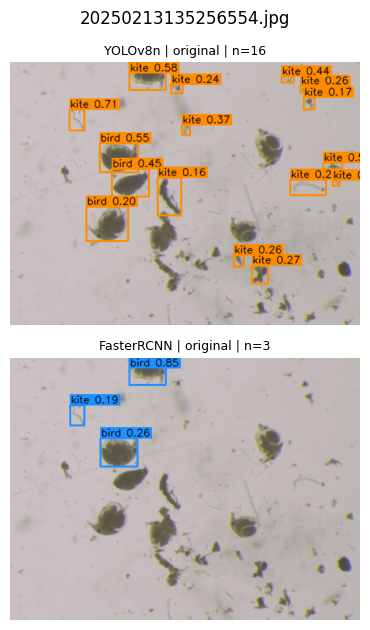

FasterRCNN: 20250213132036072.jpg — не покрыто блобов: 10


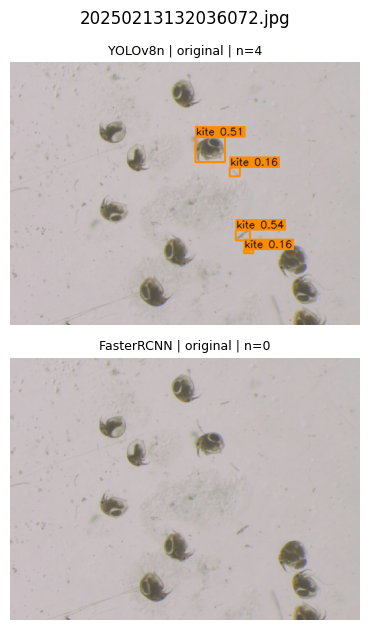

In [19]:
# Кандидаты в пропуски: кадры с максимумом непокрытых объектов - для каждого детектора.
for det in DETECTORS:
    det_cases = [c for c in MISS_CASES if c[0] == det]
    worst = sorted(det_cases, key=lambda c: -c[2])[:2]

    for _, name, n in worst:
        print(f'{det}: {name} - не покрыто блобов: {n}')
        show_det_grid(name, [])

А пропусков у обеиз моделей действительно много - они пропускают планктон, если его много мелкого, но пыль иногда принимают за объекты. Интересно, что FasterRCNN иногда отмечает всю картинку полностью как обеденный стол или раковину.

## 3. Сегментация по рамкам детектора
Оба метода получают одни и те же рамки одного детектора (исходные изображения). Рамки >60 % кадра и короче 100 px отфильтровываются (в исходной версии одна рамка на весь кадр давала GrabCut 64 с и маску в 320 тыс. px) - фильтрация логируется в `segmentation_boxes.csv`. Для кадров без рамок можно задать `MANUAL_BOXES` - такие рамки помечаются `box_source='manual'`.

In [20]:
# --- выбор детектора и рамок ---
def usable(df):
    df = df.copy()
    df['box_w'] = df.x2 - df.x1
    df['box_h'] = df.y2 - df.y1

    small_enough = df.box_area_frac <= SEG_MAX_BOX_AREA_FRAC
    large_enough = df[['box_w', 'box_h']].min(axis=1) >= SEG_MIN_BOX_SIDE
    df['used'] = small_enough & large_enough

    reason_small = np.where(df.used, '', 'too_small')
    df['filter_reason'] = np.where(
        df.box_area_frac > SEG_MAX_BOX_AREA_FRAC, 'too_large', reason_small
    )

    return df


orig_main = usable(dets_main[dets_main.aug_name == 'original'])
cov_tab = orig_main[orig_main.used].groupby('detector')
cov_tab = cov_tab.agg(images=('image', 'nunique'), boxes=('image', 'size'))
display(cov_tab)

if SEGMENTATION_DETECTOR != 'auto':
    SEG_DET = SEGMENTATION_DETECTOR
else:
    ranked = cov_tab.sort_values(['images', 'boxes'], ascending=False)
    SEG_DET = ranked.index[0]
print('Детектор, чьи рамки идут в сегментацию:', SEG_DET)

box_columns = [
    'image', 'det_idx', 'x1', 'y1', 'x2', 'y2', 'score',
    'label', 'box_area_frac', 'used', 'filter_reason',
]
seg_boxes_all = orig_main[orig_main.detector == SEG_DET][box_columns].copy()
seg_boxes_all['box_source'] = SEG_DET
seg_boxes = seg_boxes_all[seg_boxes_all.used].copy()

manual = []
for name in PATH_BY_NAME:
    if name in set(seg_boxes.image) or name not in MANUAL_BOXES:
        continue

    image_area = IMG_HW[name][0] * IMG_HW[name][1]

    for i, b in enumerate(MANUAL_BOXES[name]):
        area_frac = (b['x2'] - b['x1']) * (b['y2'] - b['y1']) / image_area

        manual.append({
            'image': name,
            'det_idx': i,
            **{k: b[k] for k in ('x1', 'y1', 'x2', 'y2')},
            'score': b.get('score', 1.0),
            'label': b.get('label', 'manual'),
            'box_area_frac': area_frac,
            'used': True,
            'filter_reason': '',
            'box_source': 'manual',
        })

if manual:
    manual_df = pd.DataFrame(manual)
    seg_boxes = pd.concat([seg_boxes, manual_df], ignore_index=True)
    seg_boxes_all = pd.concat([seg_boxes_all, manual_df], ignore_index=True)

seg_boxes = seg_boxes.reset_index(drop=True)
seg_boxes_all.to_csv(TABLE_DIR / 'segmentation_boxes.csv', index=False)

boxed_images = set(seg_boxes.image)
no_boxes = [n for n in PATH_BY_NAME if n not in boxed_images]

print(f'Рамок в сегментацию: {len(seg_boxes)} на {seg_boxes.image.nunique()} кадрах; отфильтровано: {int((~seg_boxes_all.used).sum())}; ручных: {len(manual)}')
print('Кадры без рамок (кандидаты на MANUAL_BOXES):', no_boxes)

,images,boxes
detector,,
FasterRCNN,44,139
YOLOv8n,48,326


Детектор, чьи рамки идут в сегментацию: YOLOv8n
Рамок в сегментацию: 326 на 48 кадрах; отфильтровано: 37; ручных: 0
Кадры без рамок (кандидаты на MANUAL_BOXES): ['0005.jpg', '20250213132329383.jpg']


In [21]:
# --- SAM 2 (обязательная часть задания) ---
import importlib.util


if importlib.util.find_spec('sam2') is None:
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q',
        'git+https://github.com/facebookresearch/sam2.git',
    ])

SAM2_CHECKPOINT = CKPT_DIR / 'sam2.1_hiera_large.pt'

if not SAM2_CHECKPOINT.exists() or SAM2_CHECKPOINT.stat().st_size < 800e6:
    subprocess.check_call(['wget', '-q', '-O', str(SAM2_CHECKPOINT), SAM2_URL])

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor


sam2_model = build_sam2(SAM2_CONFIG, str(SAM2_CHECKPOINT), device=DEVICE)
sam2_predictor = SAM2ImagePredictor(sam2_model)
print('SAM 2 готов, чекпойнт %.0f МБ' % (SAM2_CHECKPOINT.stat().st_size / 1e6))


def sam2_encode(rgb):
    _sync()
    t0 = time.perf_counter()

    with torch.inference_mode():
        sam2_predictor.set_image(rgb)

    _sync()
    return time.perf_counter() - t0


def sam2_box_mask(box):
    box_xyxy = np.array(
        [box['x1'], box['y1'], box['x2'], box['y2']], np.float32
    )

    _sync()
    t0 = time.perf_counter()

    with torch.inference_mode():
        masks, scores, _ = sam2_predictor.predict(
            box=box_xyxy, multimask_output=SAM2_MULTIMASK
        )

    _sync()
    elapsed = time.perf_counter() - t0

    best = int(np.argmax(scores))
    mask = (masks[best] > 0).astype(np.uint8) * 255

    return mask, float(scores[best]), elapsed

SAM 2 готов, чекпойнт 898 МБ


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [22]:
def grabcut_mask(rgb, box):
    H, W = rgb.shape[:2]
    x1 = max(0, int(round(box['x1'])))
    y1 = max(0, int(round(box['y1'])))
    x2 = min(W, int(round(box['x2'])))
    y2 = min(H, int(round(box['y2'])))
    bw = x2 - x1
    bh = y2 - y1
    out = np.zeros((H, W), np.uint8)

    if bw < 2 or bh < 2:
        return out, False

    margin = max(10, int(round(GRABCUT_MARGIN * max(bw, bh))))
    cx1 = max(0, x1 - margin)
    cy1 = max(0, y1 - margin)
    cx2 = min(W, x2 + margin)
    cy2 = min(H, y2 + margin)

    crop = np.ascontiguousarray(rgb[cy1:cy2, cx1:cx2, ::-1])
    mask = np.zeros(crop.shape[:2], np.uint8)

    try:
        cv2.grabCut(
            crop, mask, (x1 - cx1, y1 - cy1, bw, bh),
            np.zeros((1, 65)), np.zeros((1, 65)),
            GRABCUT_ITERS, cv2.GC_INIT_WITH_RECT,
        )
    except cv2.error as e:
        warnings.warn(f'GrabCut failed: {e}')
        return out, False

    foreground = (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD)
    out[cy1:cy2, cx1:cx2][foreground] = 255

    return out, True


def mask_metrics(mask, box):
    m = (mask > 0).astype(np.uint8)
    area = int(m.sum())
    H, W = m.shape

    x1 = max(0, int(box['x1']))
    y1 = max(0, int(box['y1']))
    x2 = min(W, int(box['x2']))
    y2 = min(H, int(box['y2']))
    box_area = max((x2 - x1) * (y2 - y1), 1)

    if area == 0:
        empty_metrics = {
            'mask_pixels': 0,
            'fill_ratio': 0.0,
            'outside_box_frac': np.nan,
            'n_components': 0,
            'touches_box_edge': False,
            'thin_fraction': np.nan,
            'solidity': np.nan,
        }
        return empty_metrics

    sub = m[y1:y2, x1:x2]
    bx, by, bw, bh = cv2.boundingRect(m)
    win = m[by:by + bh, bx:bx + bw]

    k = max(3, int(0.04 * max(x2 - x1, y2 - y1)) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    opened = cv2.morphologyEx(win, cv2.MORPH_OPEN, kernel)

    contours, _ = cv2.findContours(win, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hull_area = cv2.contourArea(cv2.convexHull(np.vstack(contours)))

    if sub.size:
        band = np.concatenate([
            sub[:2].ravel(),
            sub[-2:].ravel(),
            sub[:, :2].ravel(),
            sub[:, -2:].ravel(),
        ])
    else:
        band = np.zeros(1)

    metrics = {
        'mask_pixels': area,
        'fill_ratio': area / box_area,
        'outside_box_frac': 1 - float(sub.sum()) / area,
        'n_components': int(cv2.connectedComponents(win)[0] - 1),
        'touches_box_edge': bool(band.any()),
        'thin_fraction': 1 - float(opened.sum()) / area,
        'solidity': area / hull_area if hull_area > 0 else np.nan,
    }

    return metrics


def box_contrast(gray, box):
    H, W = gray.shape
    x1 = max(0, int(box['x1']))
    y1 = max(0, int(box['y1']))
    x2 = min(W, int(box['x2']))
    y2 = min(H, int(box['y2']))

    margin = int(0.2 * max(x2 - x1, y2 - y1))
    win = gray[max(0, y1 - margin):min(H, y2 + margin),
               max(0, x1 - margin):min(W, x2 + margin)]
    inner = gray[y1:y2, x1:x2]

    if win.size <= inner.size or inner.size == 0:
        return np.nan

    ring_sum = win.sum(dtype=np.float64) - inner.sum(dtype=np.float64)
    ring_mean = ring_sum / (win.size - inner.size)

    # фон − объект (>0: объект темнее)
    return float(ring_mean - inner.mean())


def overlay_mask(img, mask, color=(0, 255, 0)):
    out = img.astype(np.float32).copy()
    m = mask > 0

    out[m] = 0.55 * out[m] + 0.45 * np.array(color, np.float32)
    out = out.astype(np.uint8)

    contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, contours, -1, color, 2)

    return out


def seg_panel(rgb, box, gc, sam, expand=0.2):
    H, W = rgb.shape[:2]
    bw = box['x2'] - box['x1']
    bh = box['y2'] - box['y1']
    m = int(expand * max(bw, bh)) + 10

    X1 = max(0, int(box['x1']) - m)
    Y1 = max(0, int(box['y1']) - m)
    X2 = min(W, int(box['x2']) + m)
    Y2 = min(H, int(box['y2']) + m)

    c = rgb[Y1:Y2, X1:X2].copy()
    sc = 260 / c.shape[0]

    def rs(a, nn=False):
        interp = cv2.INTER_NEAREST if nn else cv2.INTER_AREA
        return cv2.resize(a, None, fx=sc, fy=sc, interpolation=interp)

    def to3(a):
        return np.repeat(a[..., None], 3, 2)

    c0 = c.copy()
    top_left = (int(box['x1']) - X1, int(box['y1']) - Y1)
    bottom_right = (int(box['x2']) - X1, int(box['y2']) - Y1)
    cv2.rectangle(c0, top_left, bottom_right, (255, 0, 0), 3)

    g = gc[Y1:Y2, X1:X2]
    s = sam[Y1:Y2, X1:X2]

    tiles = [
        ('image+box', rs(c0)),
        ('GrabCut mask', rs(to3(g), True)),
        ('GrabCut overlay', rs(overlay_mask(c, g))),
        ('SAM2 mask', rs(to3(s), True)),
        ('SAM2 overlay', rs(overlay_mask(c, s, (255, 0, 255)))),
    ]

    titled = []
    for name, tile in tiles:
        titled.append(add_title(tile, name) if tile.shape[1] > 200 else tile)

    return np.hstack(titled)


def inst_overlay(rgb, masks, boxes, max_side=800):
    sc = max_side / max(rgb.shape[:2])
    resized = cv2.resize(rgb, None, fx=sc, fy=sc, interpolation=cv2.INTER_AREA)
    out = resized.astype(np.float32)

    for i, (m, _) in enumerate(zip(masks, boxes)):
        hsv = np.uint8([[[(i * 37) % 180, 220, 255]]])
        col = np.array(cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)[0, 0], np.float32)

        resized_mask = cv2.resize(m, (out.shape[1], out.shape[0]), interpolation=cv2.INTER_NEAREST)
        ms = resized_mask > 0
        out[ms] = 0.5 * out[ms] + 0.5 * col

    return out.astype(np.uint8)

In [23]:
seg_rows = []
pair_rows = []
sam_encode_time = {}

for n_img, (name, g) in enumerate(seg_boxes.groupby('image')):
    rgb = load_rgb(PATH_BY_NAME[name])
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    boxes = g.sort_values('det_idx').to_dict('records')
    t_enc = sam2_encode(rgb)

    sam_encode_time[name] = t_enc
    gcs = []
    sams = []

    for i, b in enumerate(boxes):
        stem = f'{Path(name).stem}__box{i:03d}'

        t0 = time.perf_counter()
        gc, ok = grabcut_mask(rgb, b)
        t_gc = time.perf_counter() - t0

        sm, sscore, t_sam = sam2_box_mask(b)
        gcs.append(gc)
        sams.append(sm)

        pg = MASK_DIR / f'{stem}__grabcut.png'
        ps = MASK_DIR / f'{stem}__sam2.png'
        cv2.imwrite(str(pg), gc)
        cv2.imwrite(str(ps), sm)

        pp = PANEL_DIR / f'{stem}__panel.jpg'
        panel = cv2.cvtColor(seg_panel(rgb, b, gc, sm), cv2.COLOR_RGB2BGR)
        cv2.imwrite(str(pp), panel, [cv2.IMWRITE_JPEG_QUALITY, 85])

        base = {
            'image': name,
            'box_id': i,
            'box_source': b['box_source'],
            'det_label': b['label'],
            'det_score': b['score'],
            'x1': b['x1'],
            'y1': b['y1'],
            'x2': b['x2'],
            'y2': b['y2'],
            'panel_path': str(pp.relative_to(PROJECT_ROOT)),
        }

        seg_rows.append({
            **base,
            'method': 'GrabCut',
            'seconds_prompt': t_gc,
            'seconds_amortized': t_gc,
            'ok': ok,
            'sam2_pred_iou': np.nan,
            **mask_metrics(gc, b),
            'mask_path': str(pg.relative_to(PROJECT_ROOT)),
        })

        seg_rows.append({
            **base,
            'method': 'SAM 2',
            'seconds_prompt': t_sam,
            'seconds_amortized': t_sam + t_enc / len(boxes),
            'ok': True,
            'sam2_pred_iou': sscore,
            **mask_metrics(sm, b),
            'mask_path': str(ps.relative_to(PROJECT_ROOT)),
        })

        gc_mask = gc > 0
        sam_mask = sm > 0
        box_xyxy = [b['x1'], b['y1'], b['x2'], b['y2']]

        others = []
        for j, other in enumerate(boxes):
            if j == i:
                continue
            other_xyxy = [other['x1'], other['y1'], other['x2'], other['y2']]
            others.append(iou_matrix([box_xyxy], [other_xyxy])[0, 0])

        intersection = (gc_mask & sam_mask).sum()
        union = (gc_mask | sam_mask).sum()

        pair_rows.append({
            'image': name,
            'box_id': i,
            'iou_gc_sam2': float(intersection / max(union, 1)),
            'sam2_pred_iou': sscore,
            'box_overlap_iou': max(others, default=0.0),
            'box_area_frac': b['box_area_frac'],
            'box_contrast': box_contrast(gray, b),
        })

    boxes_view = draw_dets(rgb, boxes, (255, 0, 0), 800, label=False)
    view_height = int(800 * rgb.shape[0] / rgb.shape[1])
    boxes_view = cv2.resize(boxes_view, (800, view_height))

    ov = np.hstack([
        add_title(boxes_view, 'original + boxes'),
        add_title(inst_overlay(rgb, gcs, boxes), 'GrabCut masks'),
        add_title(inst_overlay(rgb, sams, boxes), 'SAM2 masks'),
    ])

    overlay_path = OVERLAY_DIR / f'{Path(name).stem}__overlay.jpg'
    cv2.imwrite(
        str(overlay_path),
        cv2.cvtColor(ov, cv2.COLOR_RGB2BGR),
        [cv2.IMWRITE_JPEG_QUALITY, 85],
    )

    if (n_img + 1) % 10 == 0:
        print(f'  сегментировано кадров: {n_img + 1}')


seg_df = pd.DataFrame(seg_rows)
pair_df = pd.DataFrame(pair_rows)

seg_df.to_csv(TABLE_DIR / 'segmentation_results.csv', index=False)
pair_df.to_csv(TABLE_DIR / 'segmentation_pairs.csv', index=False)

seg_config = {}
for key in RUN_CONFIG:
    if key.startswith(('GRABCUT', 'SAM2', 'SEG')):
        seg_config[key] = RUN_CONFIG[key]

seg_payload = {
    'config': seg_config,
    'segmentation_detector': SEG_DET,
    'results': seg_df.round(5).to_dict('records'),
}
seg_json = json.dumps(seg_payload, ensure_ascii=False, default=str)
(TABLE_DIR / 'segmentation_results.json').write_text(seg_json)

print('Масок:', len(seg_df), '| рамок:', len(pair_df))

  сегментировано кадров: 10
  сегментировано кадров: 20
  сегментировано кадров: 30
  сегментировано кадров: 40
Масок: 652 | рамок: 326


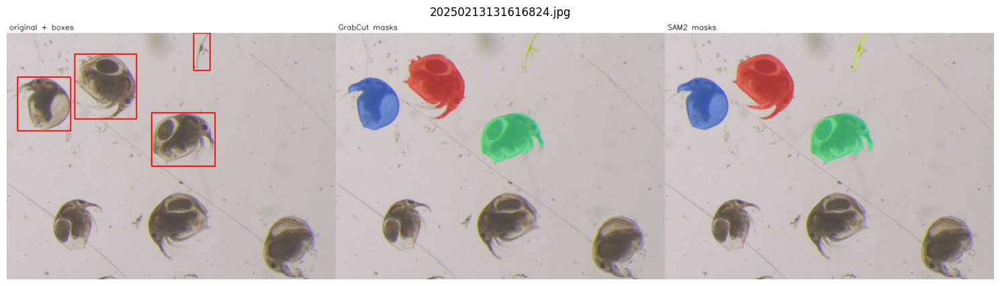

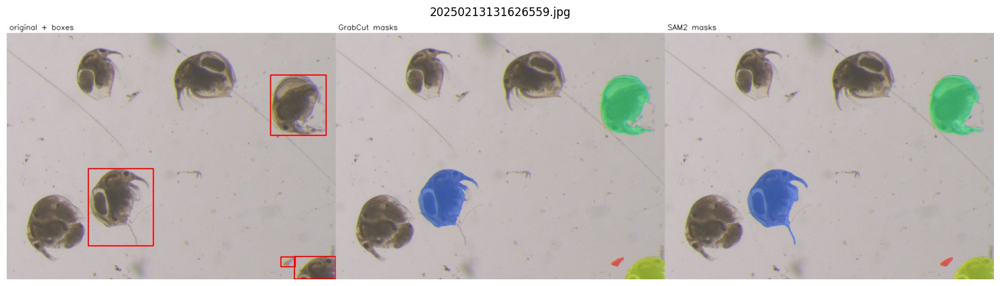

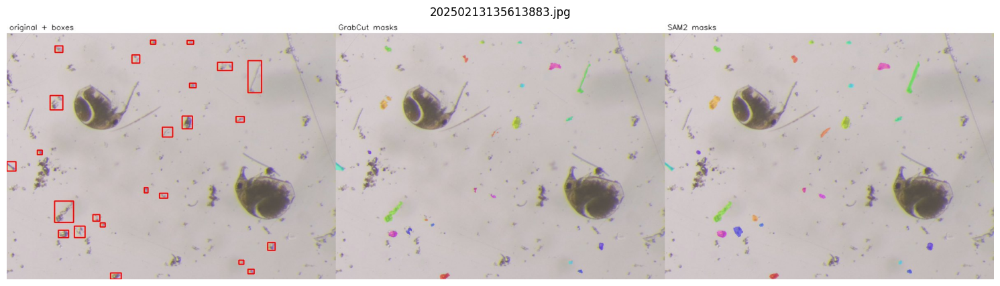

In [24]:
# Визуализация: исходник + рамки / маски / наложения для обоих методов
#  (первые 2 кадра с рамками + кадр с максимумом рамок).

first_images = list(seg_boxes.image.unique()[:2])
busiest_image = seg_boxes.image.value_counts().idxmax()
show_names = list(dict.fromkeys(first_images + [busiest_image]))

for name in show_names:
    overlay_path = OVERLAY_DIR / f'{Path(name).stem}__overlay.jpg'
    im = cv2.cvtColor(cv2.imread(str(overlay_path)), cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(20, 5))
    plt.imshow(im)
    plt.axis('off')
    plt.title(name)
    plt.show()


def show_panels(df, title, n=4):
    d = df.head(n)

    if not len(d):
        print('нет случаев')
        return

    fig, axes = plt.subplots(len(d), 1, figsize=(15, 3.4 * len(d)), squeeze=False)

    for ax, (_, r) in zip(axes.ravel(), d.iterrows()):
        panel = cv2.imread(str(PROJECT_ROOT / r.panel_path))
        ax.imshow(cv2.cvtColor(panel, cv2.COLOR_BGR2RGB))
        ax.axis('off')
        ax.set_title(f"{r.image} box{int(r.box_id)}  IoU(GC,SAM2)={r.iou_gc_sam2:.2f}", fontsize=9)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


gc_results = seg_df[seg_df.method == 'GrabCut']
gc_results = gc_results.drop(columns='method')
gc_results = gc_results.add_prefix('gc_')
gc_results = gc_results.rename(columns={'gc_image': 'image', 'gc_box_id': 'box_id'})

gc_columns = [
    'image', 'box_id', 'gc_fill_ratio', 'gc_touches_box_edge',
    'gc_thin_fraction', 'gc_mask_pixels', 'gc_panel_path',
    'gc_x1', 'gc_y1', 'gc_x2', 'gc_y2',
]
gc_results = gc_results[gc_columns]

sam_columns = [
    'image', 'box_id', 'fill_ratio', 'outside_box_frac',
    'thin_fraction', 'mask_pixels',
]
sam_results = seg_df[seg_df.method == 'SAM 2'][sam_columns]
sam_results = sam_results.rename(columns={
    'fill_ratio': 'sam_fill_ratio',
    'outside_box_frac': 'sam_outside_box_frac',
    'thin_fraction': 'sam_thin_fraction',
    'mask_pixels': 'sam_mask_pixels',
})

pairs = pair_df.merge(gc_results, on=['image', 'box_id'])
pairs = pairs.merge(sam_results, on=['image', 'box_id'])

pairs['panel_path'] = pairs.gc_panel_path
pairs.to_csv(TABLE_DIR / 'segmentation_pairs_full.csv', index=False)

### 3.1 Сравнение GrabCut и SAM 2

method,GrabCut,SAM 2
n_masks,326.000,326.000
mean_ms_prompt,368.315,13.560
mean_ms_amortized_incl_encoder,368.315,120.763
median_fill_ratio,0.425,0.601
mean_outside_box_frac,0.001,0.007
share_touch_box_edge,0.604,0.816
mean_thin_fraction,0.010,0.007
mean_solidity,0.873,0.952
mean_components,1.402,1.098
share_empty_or_tiny(<2% box),0.000,0.000


Энкодер SAM 2: 728 мс на кадр (один раз на кадр, делится между рамками).


**Согласие масок:** медиана IoU(GrabCut, SAM 2) = 0.69, доля рамок с IoU < 0.5 — 20%. `thin_fraction` — доля пикселей маски, исчезающих при морфологическом открытии (больше — сохраняется больше тонких выступов); `outside_box_frac` — доля маски SAM 2 за пределами рамки; `sam2_pred_iou` — собственная оценка SAM 2, **не** метрика качества.

,n,mean_iou,gc_fill,sam_fill,gc_touch_edge,condition
изолированная,320,0.685,0.419,0.568,0.603,overlapping
рамка перекрывается с другой,6,0.711,0.387,0.507,0.667,overlapping
малые,109,0.571,0.392,0.666,0.541,size_bin
средние,108,0.652,0.373,0.526,0.509,size_bin
крупные,109,0.832,0.489,0.507,0.761,size_bin
низкий,109,0.554,0.302,0.473,0.587,contrast_bin
средний,108,0.626,0.379,0.589,0.491,contrast_bin
высокий,109,0.875,0.573,0.639,0.734,contrast_bin


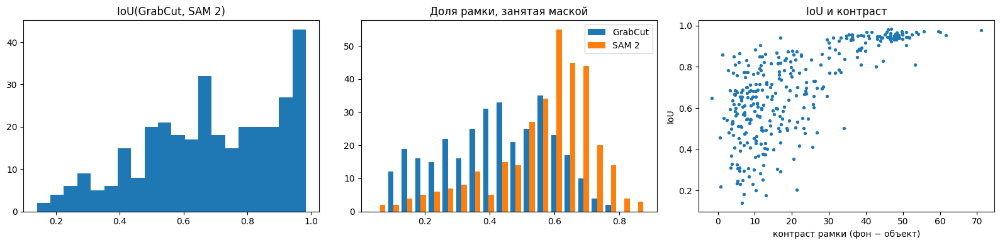

In [25]:
def seg_summary(g):
    return pd.Series({
        'n_masks': len(g),
        'mean_ms_prompt': 1000 * g.seconds_prompt.mean(),
        'mean_ms_amortized_incl_encoder': 1000 * g.seconds_amortized.mean(),
        'median_fill_ratio': g.fill_ratio.median(),
        'mean_outside_box_frac': g.outside_box_frac.mean(),
        'share_touch_box_edge': g.touches_box_edge.mean(),
        'mean_thin_fraction': g.thin_fraction.mean(),
        'mean_solidity': g.solidity.mean(),
        'mean_components': g.n_components.mean(),
        'share_empty_or_tiny(<2% box)': (g.fill_ratio < 0.02).mean(),
        'mean_sam2_pred_iou': g.sam2_pred_iou.mean(),
    })


seg_summary_df = seg_df.groupby('method')
seg_summary_df = seg_summary_df.apply(seg_summary, include_groups=False)
seg_summary_df = seg_summary_df.T.round(3)
seg_summary_df.to_csv(TABLE_DIR / 'segmentation_comparison.csv')
display(seg_summary_df)

enc = pd.Series(sam_encode_time)
print(f'Энкодер SAM 2: {1000 * enc.mean():.0f} мс на кадр (один раз на кадр, делится между рамками).')

agreement_text = (
    f"**Согласие масок:** медиана IoU(GrabCut, SAM 2) = {pairs.iou_gc_sam2.median():.2f}, "
    f"доля рамок с IoU < 0.5 - {(pairs.iou_gc_sam2 < 0.5).mean():.0%}. "
    "`thin_fraction` - доля пикселей маски, исчезающих при морфологическом открытии (больше - сохраняется больше тонких выступов); "
    "`outside_box_frac` - доля маски SAM 2 за пределами рамки; `sam2_pred_iou` - собственная оценка SAM 2, **не** метрика качества."
)
display(Markdown(agreement_text))


# по условиям: перекрывающиеся рамки, размер, контраст
pairs['overlapping'] = np.where(
    pairs.box_overlap_iou > 0.05, 'рамка перекрывается с другой', 'изолированная'
)
pairs['size_bin'] = pd.qcut(
    pairs.box_area_frac, 3, labels=['малые', 'средние', 'крупные'], duplicates='drop'
)
pairs['contrast_bin'] = pd.qcut(
    pairs.box_contrast, 3, labels=['низкий', 'средний', 'высокий'], duplicates='drop'
)

condition_tables = []
for column in ['overlapping', 'size_bin', 'contrast_bin']:
    grouped = pairs.groupby(column, observed=True)
    table = grouped.agg(
        n=('iou_gc_sam2', 'size'),
        mean_iou=('iou_gc_sam2', 'mean'),
        gc_fill=('gc_fill_ratio', 'mean'),
        sam_fill=('sam_fill_ratio', 'mean'),
        gc_touch_edge=('gc_touches_box_edge', 'mean'),
    )
    condition_tables.append(table.assign(condition=column))

cond = pd.concat(condition_tables).round(3)
cond.to_csv(TABLE_DIR / 'segmentation_by_condition.csv')
display(cond)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].hist(pairs.iou_gc_sam2, 20)
ax[0].set_title('IoU(GrabCut, SAM 2)')

ax[1].hist([pairs.gc_fill_ratio, pairs.sam_fill_ratio], 20, label=['GrabCut', 'SAM 2'])
ax[1].legend()
ax[1].set_title('Доля рамки, занятая маской')

ax[2].scatter(pairs.box_contrast, pairs.iou_gc_sam2, s=8)
ax[2].set_xlabel('контраст рамки (фон − объект)')
ax[2].set_ylabel('IoU')
ax[2].set_title('IoU и контраст')

plt.tight_layout()
fig.savefig(ANALYSIS_DIR / 'segmentation_stats.png', dpi=100)
plt.show()

In [26]:
# Устойчивость сегментации: шум и неточные рамки (одно и то же подмножество рамок;
#  IoU с маской того же метода на чистом кадре/точной рамке).

from functools import partial


def keep_box(b):
    return b


def shift_box(b, f, H, W):
    bw = b['x2'] - b['x1']
    bh = b['y2'] - b['y1']

    return {
        **b,
        'x1': max(0, b['x1'] - f * bw),
        'y1': max(0, b['y1'] - f * bh),
        'x2': min(W, b['x2'] + f * bw),
        'y2': min(H, b['y2'] + f * bh),
    }


def jitter_box(b, H, W):
    # сдвиг на 15% размера вправо-вниз
    bw = b['x2'] - b['x1']
    bh = b['y2'] - b['y1']

    return {
        **b,
        'x1': min(W - 2, b['x1'] + 0.15 * bw),
        'y1': min(H - 2, b['y1'] + 0.15 * bh),
        'x2': min(W, b['x2'] + 0.15 * bw),
        'y2': min(H, b['y2'] + 0.15 * bh),
    }


rs = np.random.default_rng(SEED)
sub = seg_boxes.reset_index(drop=True).iloc[rs.permutation(len(seg_boxes))[:ROBUST_N_BOXES]]

rob = []

# индекс базовых масок: box_id внутри кадра = порядок по det_idx
for name, g in sub.groupby('image'):
    rgb = load_rgb(PATH_BY_NAME[name])
    H, W = rgb.shape[:2]

    image_boxes = seg_boxes[seg_boxes.image == name].sort_values('det_idx')
    order = {r.det_idx: i for i, r in enumerate(image_boxes.itertuples())}

    conds = [
        ('шум σ=20', apply_aug(rgb, 'noise_medium', name), keep_box),
        ('шум σ=40', apply_aug(rgb, 'noise_strong', name), keep_box),
        ('рамка +15% (шире)', rgb, partial(shift_box, f=0.15, H=H, W=W)),
        ('рамка −15% (уже)', rgb, partial(shift_box, f=-0.15, H=H, W=W)),
        ('рамка сдвинута 15%', rgb, partial(jitter_box, H=H, W=W)),
    ]

    for cname, img, transform_box in conds:
        sam2_encode(img)

        for _, row in g.iterrows():
            box = row.to_dict()
            i = order[box['det_idx']]
            new_box = transform_box(box)
            stem = f'{Path(name).stem}__box{i:03d}'

            gc, _ = grabcut_mask(img, new_box)
            sm, _, _ = sam2_box_mask(new_box)

            for meth, new, suffix in (('GrabCut', gc, 'grabcut'), ('SAM 2', sm, 'sam2')):
                base_path = MASK_DIR / f'{stem}__{suffix}.png'
                base = cv2.imread(str(base_path), 0) > 0
                nw = new > 0

                iou = (base & nw).sum() / max((base | nw).sum(), 1)

                rob.append({
                    'condition': cname,
                    'method': meth,
                    'image': name,
                    'iou_vs_baseline': float(iou),
                })


rob_df = pd.DataFrame(rob)
rob_tab = rob_df.groupby(['condition', 'method'], sort=False)
rob_tab = rob_tab.iou_vs_baseline.agg(['mean', 'median', 'count']).round(3)
rob_tab.to_csv(TABLE_DIR / 'segmentation_robustness.csv')
display(rob_tab)

mean  median  count
condition          method                       
шум σ=20           GrabCut  0.177   0.000     40
                   SAM 2    0.856   0.863     40
шум σ=40           GrabCut  0.142   0.000     40
                   SAM 2    0.835   0.834     40
рамка +15% (шире)  GrabCut  0.812   0.890     40
                   SAM 2    0.845   0.842     40
рамка −15% (уже)   GrabCut  0.400   0.417     40
                   SAM 2    0.787   0.774     40
рамка сдвинута 15% GrabCut  0.656   0.722     40
                   SAM 2    0.881   0.879     40

## 4. Анализ результатов
### 4.1 Сводная таблица: 4 эксперимента детекции + 2 метода сегментации

In [27]:
P_DET = f"conf>={DET_CONF}, NMS IoU={DET_NMS_IOU} (class-agnostic), max {DET_MAX}"
rows = []

for r in det_summary.itertuples():
    params = P_DET

    if r.detector == 'YOLOv8n':
        params += f", imgsz={YOLO_IMGSZ}"
    else:
        params += ", вход ~800-1333 px"

    if r.data_variant != 'original':
        params += f"; аугм.: {', '.join(DET_AUG_NAMES)}"

    result = (
        f'{r.total_detections} рамок; '
        f'{r.mean_det_per_run:.2f} рамок/запуск; '
        f'{r.share_runs_with_detections:.0%} запусков с ≥1 рамкой; '
        f'ср. score {r.mean_score:.2f}'
    )

    rows.append({
        '№': f'Эксп. {r.exp_id}',
        'этап': 'детекция',
        'метод': r.detector,
        'данные': r.data_variant,
        'параметры': params,
        'единиц обработки': r.n_runs,
        'среднее время, мс': round(r.mean_ms, 1),
        'результат': result,
    })

for meth in ['GrabCut', 'SAM 2']:
    g = seg_df[seg_df.method == meth]

    if meth == 'GrabCut':
        par = f"рамки {SEG_DET}; iters={GRABCUT_ITERS}, кроп с запасом {GRABCUT_MARGIN:.0%}"
    else:
        par = f"рамки {SEG_DET}; sam2.1_hiera_large, box prompt, multimask={SAM2_MULTIMASK}"

    result = (
        f'медиана заполнения рамки {g.fill_ratio.median():.2f}; '
        f'thin={g.thin_fraction.mean():.2f}; '
        f'выход за рамку {g.outside_box_frac.mean():.2f}; '
        f'IoU(GC,SAM2) медиана {pairs.iou_gc_sam2.median():.2f}'
    )

    rows.append({
        '№': 'Сегм.',
        'этап': 'сегментация',
        'метод': meth,
        'данные': 'исходные',
        'параметры': par,
        'единиц обработки': len(g),
        'среднее время, мс': round(1000 * g.seconds_amortized.mean(), 1),
        'результат': result,
    })

comparison = pd.DataFrame(rows)
comparison.to_csv(TABLE_DIR / 'experiment_comparison.csv', index=False)

with pd.option_context('display.max_colwidth', 200, 'display.width', 250):
    display(comparison)

,№,этап,метод,данные,параметры,единиц обработки,"среднее время, мс",результат
0,Эксп. 1,детекция,YOLOv8n,original,"conf>=0.15, NMS IoU=0.5 (class-agnostic), max 100, imgsz=1024",50,14.5,363 рамок; 7.26 рамок/запуск; 96% запусков с ≥1 рамкой; ср. score 0.28
1,Эксп. 2,детекция,YOLOv8n,augmented,"conf>=0.15, NMS IoU=0.5 (class-agnostic), max 100, imgsz=1024; аугм.: bc_medium, noise_medium, noise_strong, blur_medium, blur_strong, gamma_medium, rot90, flip_h",400,13.5,1910 рамок; 4.78 рамок/запуск; 90% запусков с ≥1 рамкой; ср. score 0.28
2,Эксп. 3,детекция,FasterRCNN,original,"conf>=0.15, NMS IoU=0.5 (class-agnostic), max 100, вход ~800-1333 px",50,157.9,180 рамок; 3.60 рамок/запуск; 98% запусков с ≥1 рамкой; ср. score 0.44
3,Эксп. 4,детекция,FasterRCNN,augmented,"conf>=0.15, NMS IoU=0.5 (class-agnostic), max 100, вход ~800-1333 px; аугм.: bc_medium, noise_medium, noise_strong, blur_medium, blur_strong, gamma_medium, rot90, flip_h",400,156.7,1326 рамок; 3.31 рамок/запуск; 95% запусков с ≥1 рамкой; ср. score 0.46
4,Сегм.,сегментация,GrabCut,исходные,"рамки YOLOv8n; iters=5, кроп с запасом 15%",326,368.3,"медиана заполнения рамки 0.42; thin=0.01; выход за рамку 0.00; IoU(GC,SAM2) медиана 0.69"
5,Сегм.,сегментация,SAM 2,исходные,"рамки YOLOv8n; sam2.1_hiera_large, box prompt, multimask=False",326,120.8,"медиана заполнения рамки 0.60; thin=0.01; выход за рамку 0.01; IoU(GC,SAM2) медиана 0.69"


### 4.2 Анализ ошибок и успехов
Примеры выбираются автоматически (чтобы не подбирать удобные), затем смотрятся глазами.

detector,FasterRCNN,YOLOv8n,diff
image,,,
20250213135639379.jpg,6,28,22
20250213135613883.jpg,4,25,21
20250213135610304.jpg,3,20,17
20250213135317232.jpg,2,18,16
20250213135256554.jpg,3,16,13


Максимальное расхождение детекторов:


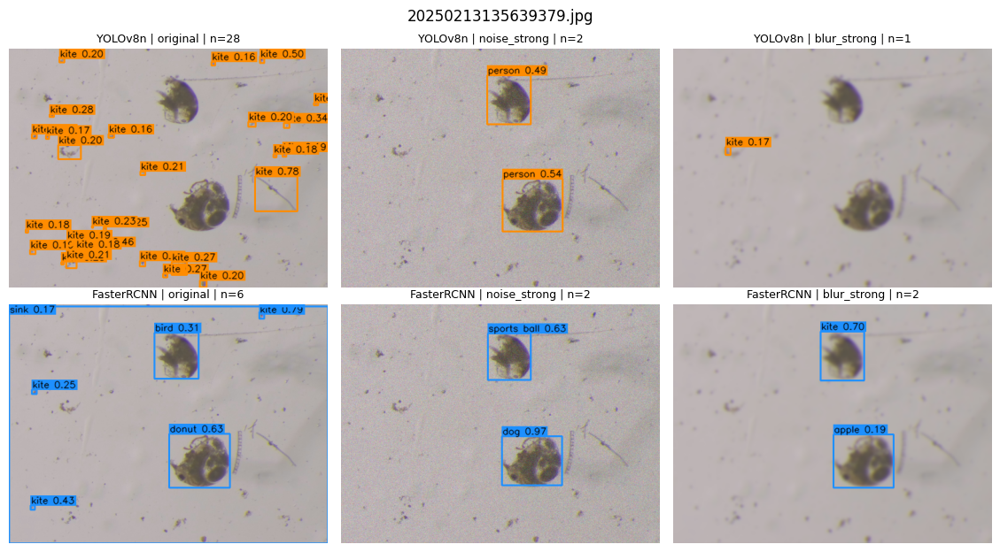

Минимальное расхождение при ненулевом числе рамок:


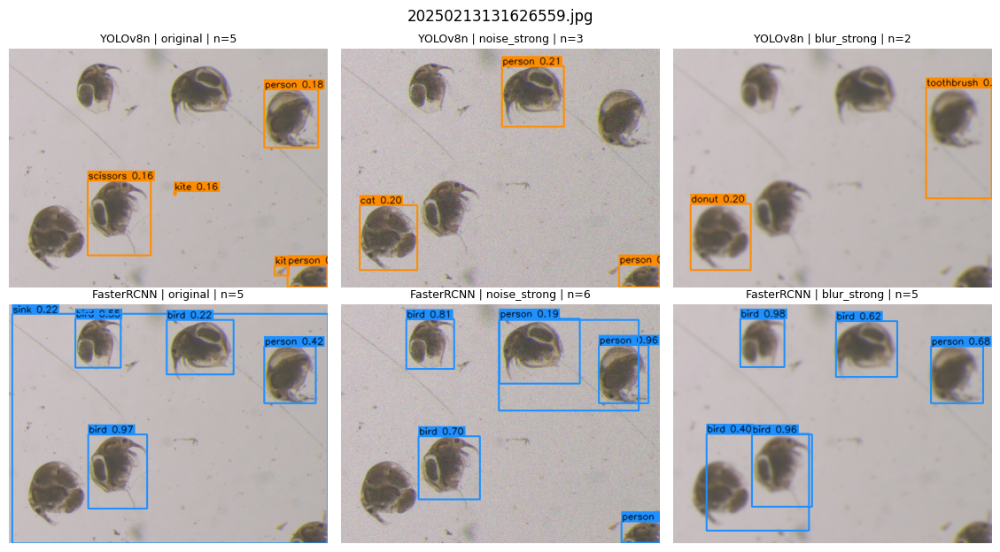

Максимум потерь при шуме σ=40: YOLOv8n, 20250213135639379.jpg, потеряно 28 из 28


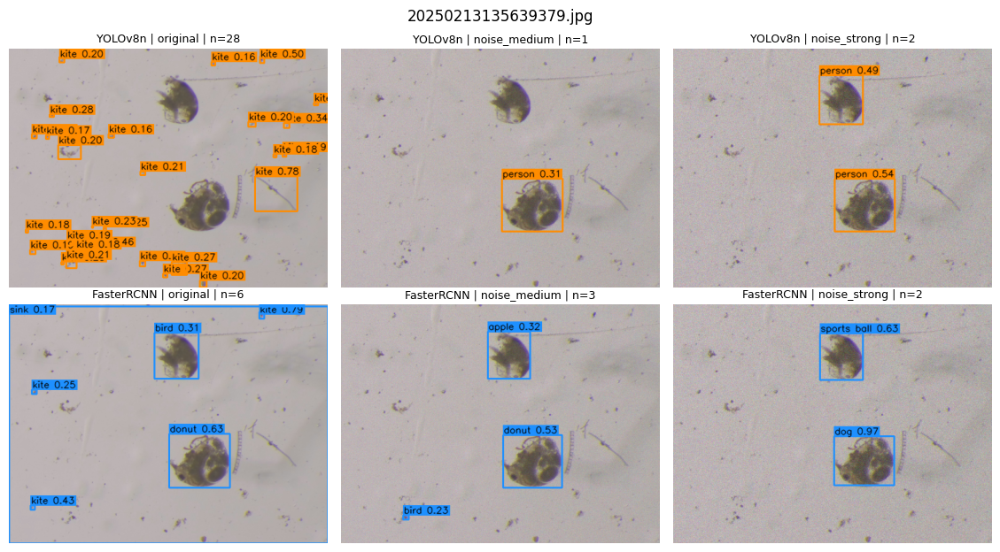

In [28]:
# Детекция: согласие/расхождение детекторов и потери при сильном шуме.
cnt = runs_df[runs_df.aug_name == 'original']
cnt = cnt.pivot(index='image', columns='detector', values='n_det')
cnt['diff'] = (cnt['YOLOv8n'] - cnt['FasterRCNN']).abs()
display(cnt.sort_values('diff', ascending=False).head(5))

print('Максимальное расхождение детекторов:')
show_det_grid(cnt['diff'].idxmax(), ['noise_strong', 'blur_strong'])

print('Минимальное расхождение при ненулевом числе рамок:')
ok_ = cnt[(cnt[['YOLOv8n', 'FasterRCNN']] > 0).all(axis=1)]

if len(ok_):
    show_det_grid(ok_['diff'].idxmin(), ['noise_strong', 'blur_strong'])

loss = stab[stab.aug_name == 'noise_strong']
loss = loss.assign(lost=lambda d: d.n_orig - d.n_match)
loss = loss.sort_values('lost', ascending=False).head(1)

for r in loss.itertuples():
    print(f'Максимум потерь при шуме σ=40: {r.detector}, {r.image}, потеряно {r.lost} из {r.n_orig}')
    show_det_grid(r.image, ['noise_medium', 'noise_strong'])

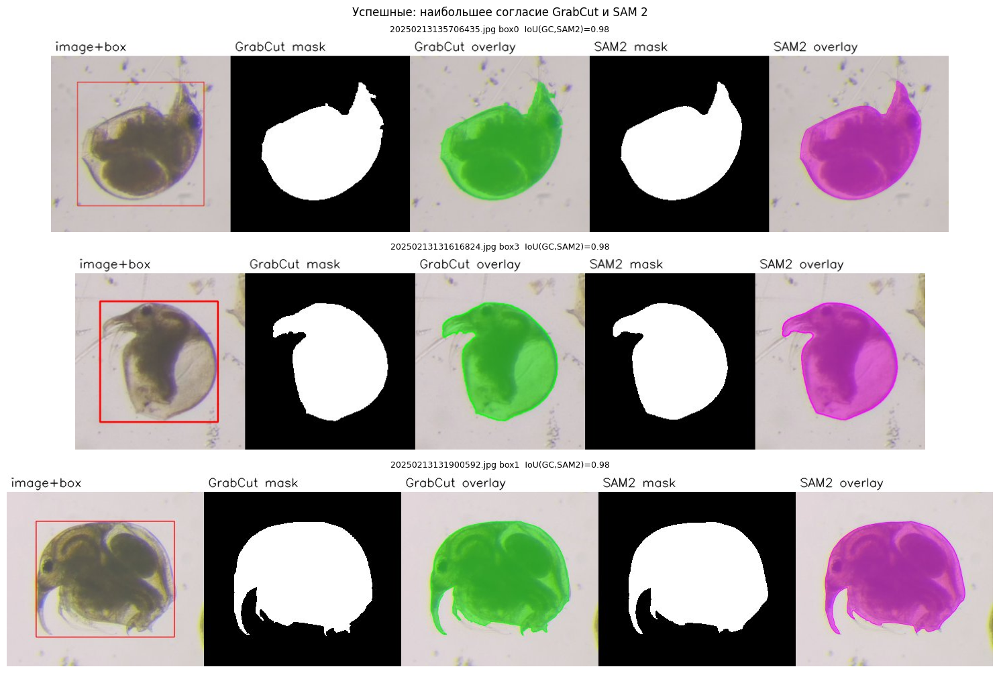

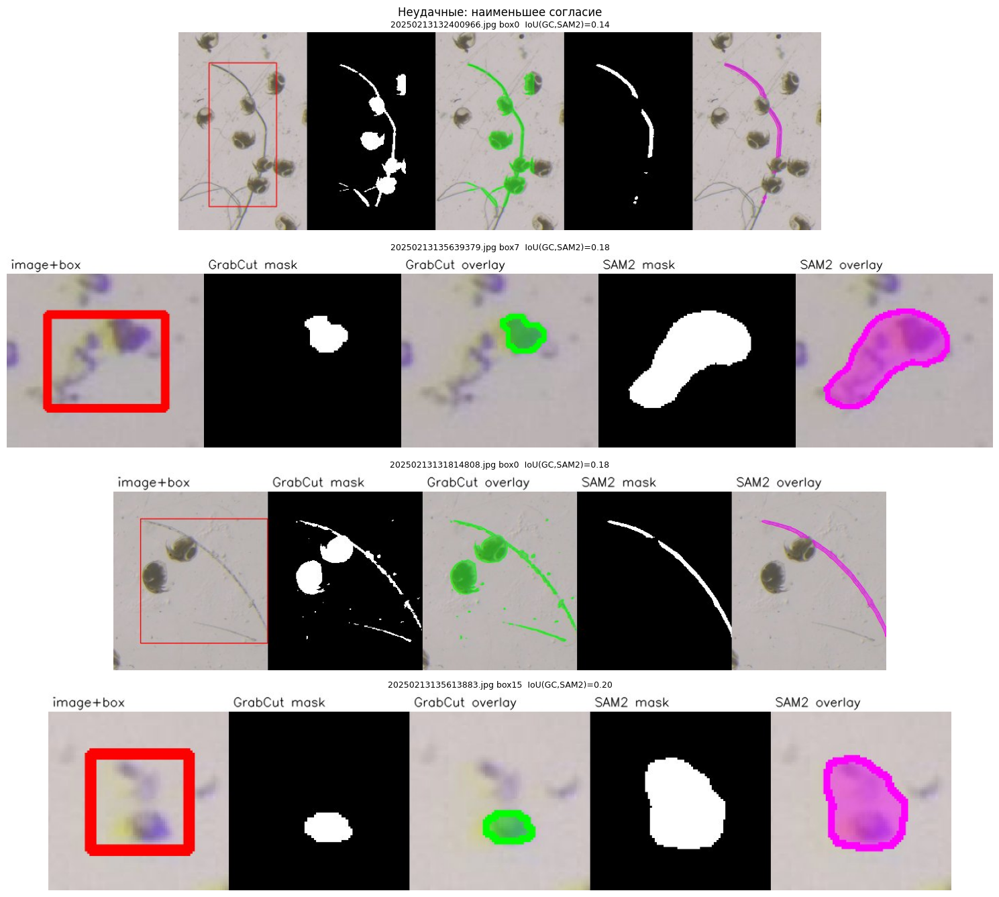

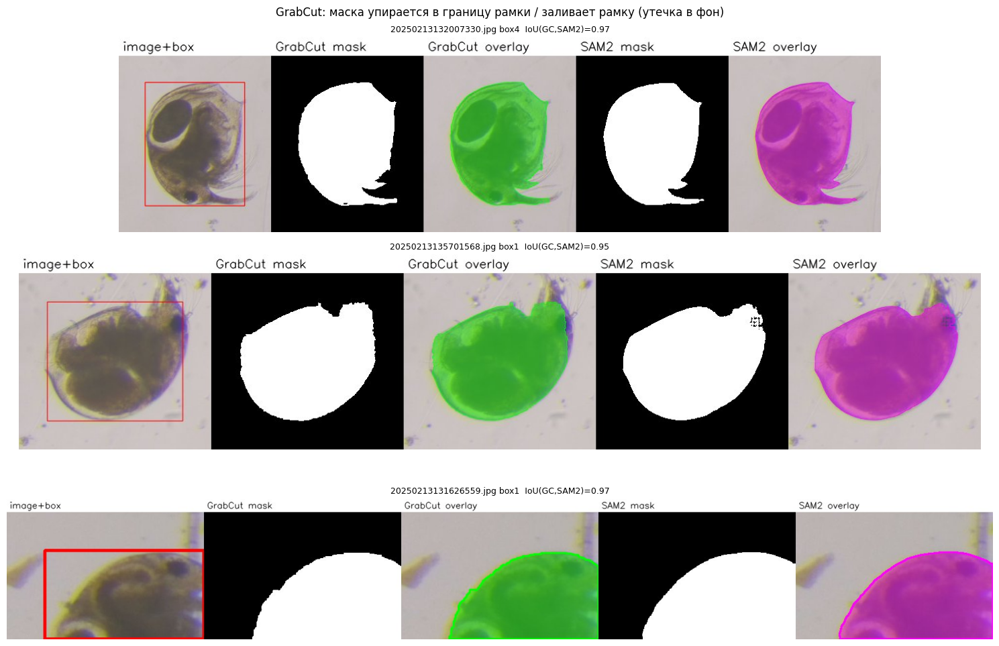

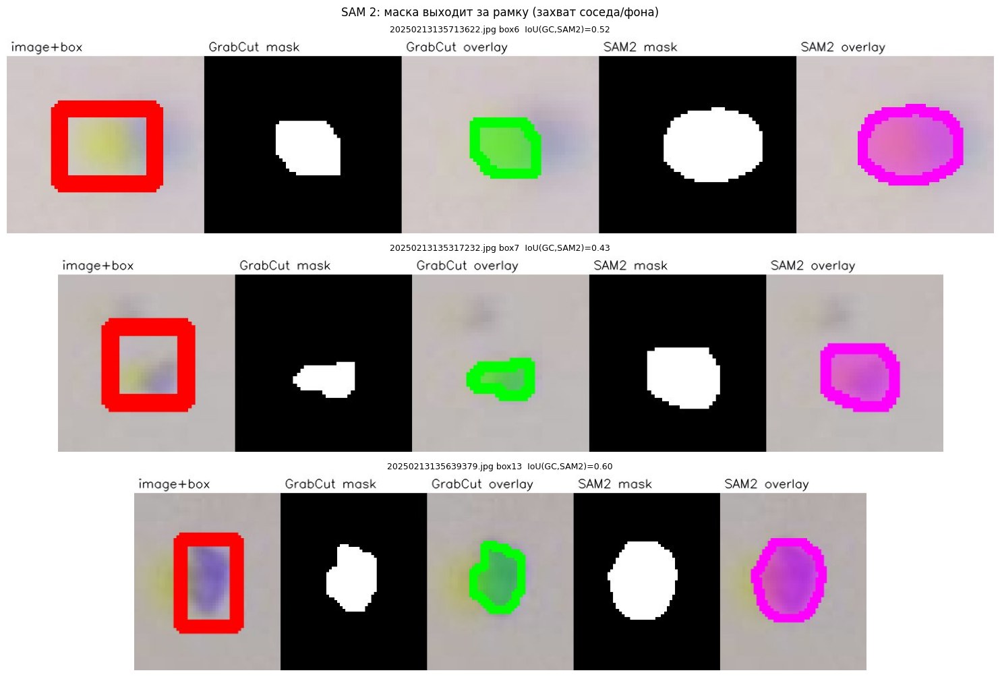

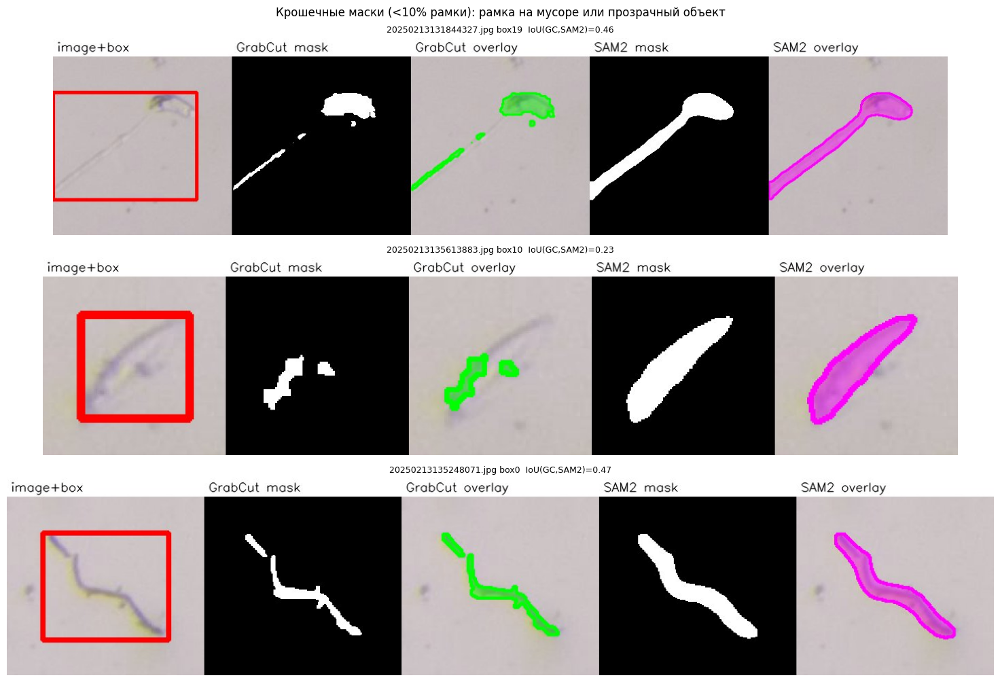

In [29]:
# Сегментация: успехи (высокое согласие) и неудачи разных типов.
show_panels(
    pairs.sort_values('iou_gc_sam2', ascending=False),
    'Успешные: наибольшее согласие GrabCut и SAM 2',
    3,
)

show_panels(
    pairs.sort_values('iou_gc_sam2'),
    'Неудачные: наименьшее согласие',
    4,
)

show_panels(
    pairs[pairs.gc_touches_box_edge].sort_values('gc_fill_ratio', ascending=False),
    'GrabCut: маска упирается в границу рамки / заливает рамку (утечка в фон)',
    3,
)

show_panels(
    pairs.sort_values('sam_outside_box_frac', ascending=False),
    'SAM 2: маска выходит за рамку (захват соседа/фона)',
    3,
)

tiny_masks = pairs[(pairs.gc_fill_ratio < 0.1) | (pairs.sam_fill_ratio < 0.1)]
show_panels(
    tiny_masks.sort_values('gc_fill_ratio'),
    'Крошечные маски (<10% рамки): рамка на мусоре или прозрачный объект',
    3,
)

In [30]:
# Причины: ранговые корреляции IoU(GC,SAM2) и качества масок с условиями.
score_column = 'det_score' if 'det_score' in pairs else 'sam2_pred_iou'
feature_columns = [
    'iou_gc_sam2', 'gc_fill_ratio', 'sam_fill_ratio', 'box_contrast',
    'box_overlap_iou', 'box_area_frac', score_column,
]

feat = pairs[feature_columns].copy()
corr = feat.corr(method='spearman').round(2)
corr.to_csv(TABLE_DIR / 'segmentation_spearman.csv')
display(corr)

kept_by_aug = stab_by_aug.reset_index()
kept_by_aug = kept_by_aug.pivot(index='aug_name', columns='detector', values='kept_rate')
kept_by_aug = kept_by_aug.round(3).rename_axis(None).T
display(kept_by_aug)

,iou_gc_sam2,gc_fill_ratio,sam_fill_ratio,box_contrast,box_overlap_iou,box_area_frac,sam2_pred_iou
iou_gc_sam2,1.00,0.80,0.11,0.68,0.14,0.61,0.82
gc_fill_ratio,0.80,1.00,0.53,0.72,0.08,0.30,0.64
sam_fill_ratio,0.11,0.53,1.00,0.43,-0.02,-0.41,0.08
box_contrast,0.68,0.72,0.43,1.00,0.11,0.39,0.77
box_overlap_iou,0.14,0.08,-0.02,0.11,1.00,0.24,0.21
box_area_frac,0.61,0.30,-0.41,0.39,0.24,1.00,0.70
sam2_pred_iou,0.82,0.64,0.08,0.77,0.21,0.70,1.00


,bc_medium,blur_medium,blur_strong,flip_h,gamma_medium,noise_medium,noise_strong,rot90
detector,,,,,,,,
FasterRCNN,0.889,0.778,0.478,0.700,0.794,0.467,0.406,0.572
YOLOv8n,0.559,0.730,0.069,0.722,0.702,0.157,0.118,0.642


### 4.3 Выводы
Числа и сравнения в блоке ниже подставляются автоматически из таблиц.

In [31]:
by = det_summary.set_index(['detector', 'data_variant'])
fast = det_summary.groupby('detector').mean_ms.mean()

original_summary = det_summary[det_summary.data_variant == 'original']
cov = original_summary.set_index('detector').share_runs_with_detections

so = stab_overall
gcm = seg_df[seg_df.method == 'GrabCut']
smm = seg_df[seg_df.method == 'SAM 2']

more_stable = so.mean_iou_matched.idxmax()
most_kept = so.kept_rate.idxmax()

yolo_orig = by.loc[('YOLOv8n', 'original')]
frcnn_orig = by.loc[('FasterRCNN', 'original')]
prx_by_det = prx.set_index('detector')

detection_text = (
    f"**Детекция.** На исходных изображениях YOLOv8n в среднем даёт {yolo_orig['mean_det_per_run']:.2f} рамок/кадр "
    f"за {yolo_orig['mean_ms']:.0f} мс, Faster R-CNN - {frcnn_orig['mean_det_per_run']:.2f} "
    f"за {frcnn_orig['mean_ms']:.0f} мс (×{fast['FasterRCNN'] / fast['YOLOv8n']:.1f} медленнее). "
    f"Хотя бы одну рамку получили {cov['YOLOv8n']:.0%} кадров у YOLO и {cov['FasterRCNN']:.0%} у Faster R-CNN. "
    f"На аугментированных данных число рамок меняется до {so.count_ratio.min():.2f}-{so.count_ratio.max():.2f} от исходного; "
    f"доля сохранившихся рамок - YOLOv8n {so.loc['YOLOv8n', 'kept_rate']:.0%}, "
    f"Faster R-CNN {so.loc['FasterRCNN', 'kept_rate']:.0%}; "
    f"среднее IoU сохранившихся - {so.loc['YOLOv8n', 'mean_iou_matched']:.2f} / {so.loc['FasterRCNN', 'mean_iou_matched']:.2f}. "
    f"Устойчивее по сохранению рамок - **{most_kept}**, по точности положения - **{more_stable}**. "
    f"По прокси-проверке доля кандидатов в ложные срабатывания: YOLOv8n {prx_by_det.loc['YOLOv8n', 'fp_candidate_share']:.0%}, "
    f"Faster R-CNN {prx_by_det.loc['FasterRCNN', 'fp_candidate_share']:.0%}; "
    f"доля непокрытых объектов (верхняя оценка): {prx_by_det.loc['YOLOv8n', 'miss_candidate_share']:.0%} / "
    f"{prx_by_det.loc['FasterRCNN', 'miss_candidate_share']:.0%}. "
    f"Для сегментации использованы рамки **{SEG_DET}** (по охвату кадров). "
    "Число рамок и score - не показатели точности: классы COCO для планктона бессмысленны, "
    "а число рамок сильно зависит от порога (см. таблицу чувствительности)."
)

segmentation_text = (
    f"**Сегментация.** Время на рамку: GrabCut {1000 * gcm.seconds_amortized.mean():.0f} мс, "
    f"SAM 2 {1000 * smm.seconds_amortized.mean():.0f} мс (с учётом энкодера, разделённого между рамками). "
    f"Медианное IoU между масками методов - {pairs.iou_gc_sam2.median():.2f}; "
    f"доля сильных расхождений (IoU<0.5) - {(pairs.iou_gc_sam2 < 0.5).mean():.0%}. "
    f"Доля тонких выступов (`thin_fraction`): GrabCut {gcm.thin_fraction.mean():.3f}, SAM 2 {smm.thin_fraction.mean():.3f}; "
    f"маска SAM 2 в среднем выходит за рамку на {smm.outside_box_frac.mean():.1%}. "
    "В тесте устойчивости (таблица выше) видно влияние шума и неточных рамок на каждый метод."
)

txt = '\n' + detection_text + '\n\n' + segmentation_text + '\n'

display(Markdown(txt))
(RESULTS_DIR / 'conclusions_numbers.md').write_text(txt)


**Детекция.** На исходных изображениях YOLOv8n в среднем даёт 7.26 рамок/кадр за 15 мс, Faster R-CNN — 3.60 за 158 мс (×11.2 медленнее). Хотя бы одну рамку получили 96% кадров у YOLO и 98% у Faster R-CNN. На аугментированных данных число рамок меняется до 0.66–0.92 от исходного; доля сохранившихся рамок — YOLOv8n 46%, Faster R-CNN 64%; среднее IoU сохранившихся — 0.91 / 0.91. Устойчивее по сохранению рамок — **FasterRCNN**, по точности положения — **YOLOv8n**. По прокси-проверке доля кандидатов в ложные срабатывания: YOLOv8n 73%, Faster R-CNN 48%; доля непокрытых объектов (верхняя оценка): 67% / 12%. Для сегментации использованы рамки **YOLOv8n** (по охвату кадров). Число рамок и score — не показатели точности: классы COCO для планктона бессмысленны, а число рамок сильно зависит от порога (см. таблицу чувствительности).

**Сегментация.** Время на рамку: GrabCut 368 мс, SAM 2 121 мс (с учётом энкодера, разделённого между рамками). Медианное IoU между масками методов — 0.69; доля сильных расхождений (IoU<0.5) — 20%. Доля тонких выступов (`thin_fraction`): GrabCut 0.010, SAM 2 0.007; маска SAM 2 в среднем выходит за рамку на 0.7%. В тесте устойчивости (таблица выше) видно влияние шума и неточных рамок на каждый метод.


1236

**Выводы о применимости** (по всему исследованию):
1. **Детекторы COCO без дообучения - только как грубый инструмент.** Класса «планктон» нет, поэтому рамки получают случайные классы (bird/person/kite и т.п.), а число и положение рамок чувствительны к порогу, размеру входа и аугментациям; confidence не равен вероятности организма; много ошибок - пропусков и ложных рамок. Пригодно для быстрого получения *кандидатов* (если смотреть class-agnostic), но не для точного автоматического подсчёта. Двухэтапный детектор тяжелее на порядок по времени, одноэтапный - быстрее; двухэтапный дает больше правильных рамок, но и ложных срабатываний больше.
2. **Аугментации.** Для микроскопии безопасны отражения/повороты 90° и умеренные яркость/контраст/гамма; сильные размытие, шум, и сильное снижение контраста разрушают тонкие морфологические признаки и часто меняют детекции (см. `detection_stability.csv`).
3. **Сегментация по рамке.** SAM 2 с box-подсказкой не требует обучения и, как правило, даёт цельные маски с аккуратной границей за доли секунды на рамку. GrabCut на порядок медленнее на полном кадре (после кропа - быстрее), чувствителен к контрасту внутри рамки и положению рамки; более точен, но склонен выделять в маску пыль и артефакты.
4. **Качество без разметки оценено только косвенно** (согласие методов, устойчивость, эвристический прокси, визуальный осмотр). Для хорошего количественного вывода нужна вручную размеченная контрольная выборка (рамки, маски) для расчёта метрик.
5. **На практике возможен такой пайплайн:** дообученный детектор -> SAM 2 по рамкам -> ручной контроль сомнительных масок.

## 5. Проверка и экспорт

In [32]:
expected = [
    'image_statistics.csv', 'blob_estimates.csv', 'augmentation_manifest.csv',
    'augmentation_quality.csv', 'detections.csv', 'detections.json',
    'detection_runs.csv', 'detection_summary.csv',
    'detection_summary_by_aug.csv', 'detection_stability.csv',
    'detection_threshold_sensitivity.csv', 'detection_proxy_check.csv',
    'segmentation_boxes.csv', 'segmentation_results.csv',
    'segmentation_results.json', 'segmentation_pairs_full.csv',
    'segmentation_comparison.csv', 'segmentation_by_condition.csv',
    'segmentation_robustness.csv', 'experiment_comparison.csv',
]
missing = [f for f in expected if not (TABLE_DIR / f).exists()]
print('Нет файлов таблиц:', missing or 'всё на месте')

for directory in [AUG_DIR, DET_DIR, MASK_DIR, PANEL_DIR, OVERLAY_DIR, ANALYSIS_DIR]:
    n_files = len([f for f in directory.rglob('*') if f.is_file()])
    print(f'{directory.relative_to(PROJECT_ROOT)}: {n_files} файлов')

assert not missing and len(list(DET_DIR.glob('*.jpg'))) == len(paths_for_exp)

requirements = [
    f'{name}=={version}'
    for name, version in ENV['packages'].items()
    if version != 'not installed'
]
(RESULTS_DIR / 'requirements_used.txt').write_text('\n'.join(requirements))
print((RESULTS_DIR / 'requirements_used.txt').read_text())

Нет файлов таблиц: всё на месте
results/augmentations: 552 файлов
results/detections: 250 файлов
results/segmentation/masks: 652 файлов
results/segmentation/panels: 326 файлов
results/segmentation/overlays: 48 файлов
results/analysis: 5 файлов
torch==2.14.1+cu130
torchvision==0.29.1+cu130
ultralytics==8.4.216
opencv-python==5.0.0.93
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scipy==1.16.3
Pillow==11.3.0
gdown==5.2.2
sam2==1.1.0
